# Laboratorio 1 — Exploración de Datos, Encuesta de Afectación Digital por el Terremoto
**Especialización en Analítica Estratégica de Datos · Estadística para Analítica de Datos · UPTC**
Profesor: Duván Cataño

**Base de datos:** Encuesta de afectación digital de entidades públicas — Terremoto del 10 de agosto de 2026 (MinTIC)
**Tipo de proyecto:** Clasificación (variable objetivo: *nivel general de afectación de las capacidades digitales*)

**Equipo:** Edwart Stevens González Ríos · Karen Julieth Hernández Chaparro · Deisy Carolina Monroy Gutiérrez

Numerales 1 a 9: selección de la base, estructura, calidad de datos, análisis univariado, variable objetivo, relaciones con el objetivo,
cruce con la pobreza multidimensional del DANE y planteamiento del problema. Al final se exportan a `data/processed/` las bases que usa el
**Laboratorio 2** (`02_Lab2_Estadistica_Asociacion.ipynb`).

Pensado para **Visual Studio Code**: abrir la carpeta del proyecto y ejecutar con *Run All*. Los datos originales se leen de `data/raw/` y los resultados se guardan en `data/processed/`.

### 0. Instalación de librerías
Ejecute esta celda primero. Revisa qué librerías faltan en el Python que usa el notebook (Colab, VS Code o Jupyter) y las instala.
Si al final pide reiniciar, use **Restart** en el kernel y vuelva a ejecutar todo desde el inicio.

In [1]:
import sys, subprocess, importlib, importlib.util
REQUERIDAS = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn',
              'scipy': 'scipy', 'openpyxl': 'openpyxl', 'sklearn': 'scikit-learn'}   # módulo -> paquete de pip
faltantes = [pip for mod, pip in REQUERIDAS.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print('Instalando:', ', '.join(faltantes))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *faltantes])
    importlib.invalidate_caches()
    print('Instalación terminada.')
else:
    print('Todas las librerías están instaladas.')
print('Python en uso:', sys.executable)
aun_faltan = [m for m in REQUERIDAS if importlib.util.find_spec(m) is None]
if aun_faltan:
    print('ATENCIÓN: siguen faltando', aun_faltan, '-> reinicie el kernel (Restart) y ejecute de nuevo esta celda.')

Todas las librerías están instaladas.
Python en uso: /usr/bin/python3


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import warnings, os
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.width', 200)

# Paleta (azul de referencia + rampa secuencial para la variable objetivo ordinal)
AZUL = '#2a78d6'; GRIS = '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 9})

In [3]:
from pathlib import Path
# Raíz del proyecto = la primera carpeta (actual o superior) que contiene data/
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir()), Path.cwd())
RAW, PROC = RAIZ / 'data' / 'raw', RAIZ / 'data' / 'processed'
PROC.mkdir(parents=True, exist_ok=True)
def ruta(nombre):
    # busca el archivo en data/raw, data/processed o la carpeta actual
    for c in [RAW / nombre, PROC / nombre, Path(nombre)]:
        if c.exists(): return str(c)
    return nombre
ARCHIVO = ruta('Resultados_encuesta_entidades_Terremoto_20261022.csv')
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files   # en Colab: subir el CSV
        files.upload()
    except ImportError:
        pass
df_raw = pd.read_csv(ARCHIVO, encoding='utf-8')
print('Dimensiones originales:', df_raw.shape)

Dimensiones originales: (409, 61)


## 1. Selección de la Base de Datos

### Generalidades
| Aspecto | Descripción |
|---|---|
| **Nombre** | Resultados de la encuesta a entidades — Afectación de capacidades digitales por el terremoto (corte 22-oct-2026) |
| **Fuente original** | Ministerio de Tecnologías de la Información y las Comunicaciones (MinTIC), formulario de diagnóstico TIC aplicado a entidades territoriales después del sismo |
| **Enlace de acceso** | Portal Nacional de Datos Abiertos (datos.gov.co): [Resultados encuesta entidades Terremoto](https://www.datos.gov.co/Ciencia-Tecnolog-a-e-Innovaci-n/Resultados-encuesta-entidades-Terremoto/v3tn-7h59/about_data). Publicado por MinTIC el 8-sep-2026, licencia CC BY-SA 4.0. Archivo usado: `Resultados_encuesta_entidades_Terremoto_20261022.csv` (descarga del 22-oct-2026). |
| **Fuente complementaria** | DANE — Medida de Pobreza Multidimensional Municipal de fuente censal 2018 ([anexo .xlsx](https://www.dane.gov.co/files/investigaciones/condiciones_vida/pobreza/2018/informacion-censal/anexo-censal-pobreza-municipal-2018.xlsx)); se cruza por municipio en la sección 7.4 |

### Contexto
El 10 de agosto de 2026 a las 7:34 a. m. ocurrió un sismo de magnitud 7,4 con epicentro en San José del Palmar (Chocó), a 103 km de profundidad;
los mayores daños se reportaron en Chocó, Caldas, Risaralda, Quindío, Cauca y Valle del Cauca (Servicio Geológico Colombiano, citado por OPS; el informe de OPS
escribe "San Juan del Palmar", pero el municipio oficial según el DANE es San José del Palmar).
Después del evento, MinTIC recogió por formulario el estado de la infraestructura y los servicios digitales de alcaldías, gobernaciones,
hospitales e instituciones educativas.

**Relevancia para un proyecto de analítica:** la encuesta permite construir un modelo que **clasifique el nivel de afectación digital** de una entidad
a partir de señales observables (conectividad, energía, estado de sistemas, personal TIC, daños físicos). Con ese modelo, MinTIC puede
**priorizar la atención** (envío de conectividad satelital, plantas eléctricas, apoyo técnico, sede electrónica de contingencia) hacia las entidades
con mayor probabilidad de estar en situación crítica, incluso cuando reportan de forma incompleta. El análisis presta especial atención al **Chocó**,
departamento del epicentro y el más pobre de los cinco de la encuesta, cruzando los datos con el índice de pobreza multidimensional municipal del DANE.

### Estructura

In [4]:
t_ini = pd.to_datetime(df_raw['Hora de inicio'], format='%Y %b %d %I:%M:%S %p')
print(f'Número de observaciones : {df_raw.shape[0]}')
print(f'Número de variables     : {df_raw.shape[1]}')
print('Unidad de observación   : una entidad pública que diligencia el formulario (alcaldía, gobernación, ESE, institución educativa, etc.)')
print(f'Periodo cubierto        : {t_ini.min():%d-%m-%Y %H:%M} a {t_ini.max():%d-%m-%Y %H:%M}  ({t_ini.dt.date.nunique()} días con respuestas)')
print('Cobertura geográfica    :', ', '.join(df_raw['Seleccione el departamento.'].value_counts().index))

Número de observaciones : 409
Número de variables     : 61
Unidad de observación   : una entidad pública que diligencia el formulario (alcaldía, gobernación, ESE, institución educativa, etc.)
Periodo cubierto        : 20-08-2026 16:06 a 03-09-2026 08:27  (14 días con respuestas)
Cobertura geográfica    : RISARALDA, VALLE DEL CAUCA, CALDAS, CHOCÓ, QUINDÍO


## 2. Descripción de las Variables (diccionario de datos)

Los nombres originales son las preguntas completas del formulario. Para trabajar se asigna a cada variable un **nombre corto en snake_case**
y se documenta su significado, unidad, valores posibles y tipología. Las preguntas de **selección múltiple** (respuestas separadas por `;`) se
clasifican como cualitativas nominales multi-respuesta; de ellas se derivan después variables indicadoras y conteos.

In [5]:
# nombre_corto, tipología, unidad, significado
DICC = [
 ('id','Cualitativa nominal','—','Identificador consecutivo de la respuesta'),
 ('hora_inicio','Variable temporal','fecha-hora','Momento en que la entidad inició el formulario'),
 ('hora_fin','Variable temporal','fecha-hora','Momento en que la entidad terminó el formulario'),
 ('correo','Cualitativa nominal','—','Correo de quien responde (anonimizado)'),
 ('nombre','Cualitativa nominal','—','Nombre de quien responde (anonimizado / vacío)'),
 ('autoriza_datos','Cualitativa nominal','—','Autorización de tratamiento de datos (Ley 1581 de 2012)'),
 ('departamento','Cualitativa nominal','—','Departamento de la entidad'),
 ('municipio','Cualitativa nominal','—','Municipio de la entidad'),
 ('tipo_entidad','Cualitativa nominal','—','Tipo de entidad (alcaldía, institución educativa, ESE, etc.)'),
 ('razon_social','Cualitativa nominal','—','Nombre de la entidad'),
 ('nivel_afectacion','Cualitativa ordinal','—','VARIABLE OBJETIVO. Nivel general de afectación de las capacidades digitales'),
 ('riesgo_continuidad','Cualitativa nominal','—','Existe situación TIC que ponga en riesgo servicios esenciales'),
 ('riesgo_continuidad_txt','Cualitativa nominal','texto libre','Descripción de la situación de riesgo'),
 ('sistemas_afectados','Cualitativa nominal','multi-respuesta','Sistemas, servicios o infraestructura tecnológica afectados'),
 ('estado_sistemas','Cualitativa ordinal','—','Estado general de los sistemas o servicios afectados'),
 ('sistemas_criticos_txt','Cualitativa nominal','texto libre','Sistemas más críticos y proceso que afectan'),
 ('energia_estable','Cualitativa ordinal','—','Suministro estable de energía eléctrica'),
 ('energia_alternativa','Cualitativa nominal','multi-respuesta','Alternativas de energía disponibles (UPS, planta, panel solar...)'),
 ('estado_conectividad','Cualitativa ordinal','—','Estado actual de la conectividad a Internet'),
 ('tipo_conexion','Cualitativa nominal','multi-respuesta','Tecnologías de conexión utilizadas'),
 ('operadores_txt','Cualitativa nominal','texto libre','Operadores de conectividad'),
 ('zonas_incomunicadas','Cualitativa nominal','—','Existen sedes/zonas incomunicadas'),
 ('zonas_incomunicadas_txt','Cualitativa nominal','texto libre','Sedes/zonas incomunicadas'),
 ('est_sist_info','Cualitativa ordinal','—','Estado de los sistemas de información institucionales'),
 ('est_correo','Cualitativa ordinal','—','Estado del correo electrónico institucional'),
 ('est_web','Cualitativa ordinal','—','Estado de la página web o sede electrónica'),
 ('est_nube','Cualitativa ordinal','—','Estado de los servicios en la nube'),
 ('est_datacenter','Cualitativa ordinal','—','Estado del centro de datos o servidores'),
 ('est_pqrsdf','Cualitativa ordinal','—','Estado de los sistemas de atención al ciudadano (PQRSDF)'),
 ('est_financiero','Cualitativa ordinal','—','Estado de los sistemas financieros, administrativos o de contratación'),
 ('servicios_fuera_txt','Cualitativa nominal','texto libre','Servicios fuera de operación, desde cuándo y proceso impactado'),
 ('sede_contingencia','Cualitativa nominal','—','Requiere sede electrónica de contingencia en gov.co'),
 ('infra_afectada','Cualitativa nominal','multi-respuesta','Infraestructura TIC afectada'),
 ('estado_infra','Cualitativa ordinal','—','Estado general de la infraestructura afectada'),
 ('danos_estructurales','Cualitativa nominal','—','Espacios con infraestructura TIC con daños estructurales o acceso restringido'),
 ('danos_txt','Cualitativa nominal','texto libre','Descripción de la condición física'),
 ('poliza_seguro','Cualitativa nominal','—','La infraestructura afectada tiene póliza de seguro vigente'),
 ('perdida_info','Cualitativa nominal','—','Pérdida, corrupción o indisponibilidad de información'),
 ('perdida_info_txt','Cualitativa nominal','texto libre','Información afectada'),
 ('backups','Cualitativa ordinal','—','Disponibilidad de copias de seguridad para recuperación'),
 ('contingencia','Cualitativa ordinal','—','Mecanismos de contingencia/recuperación y si pudieron activarse'),
 ('incidentes_ciber','Cualitativa nominal','booleano','Incidentes de seguridad digital asociados a la emergencia'),
 ('incidentes_txt','Cualitativa nominal','texto libre','Descripción de los incidentes'),
 ('control_cuentas','Cualitativa nominal','—','Control y trazabilidad de cuentas de administración'),
 ('proveedores_sla','Cualitativa nominal','—','Proveedores tecnológicos cumplen SLA y protocolos'),
 ('requiere_colcert','Cualitativa nominal','—','Requiere servicios de ColCERT'),
 ('colcert_txt','Cualitativa nominal','texto libre','Necesidad de apoyo de ColCERT'),
 ('personal_afectado','Cualitativa ordinal','—','La emergencia afectó la disponibilidad del personal TIC'),
 ('personal_suficiente','Cualitativa ordinal','—','Suficiencia de personal técnico'),
 ('areas_apoyo','Cualitativa nominal','multi-respuesta','Áreas en que requiere apoyo técnico especializado'),
 ('tramites_impedidos','Cualitativa ordinal','—','Las afectaciones impiden servicios o trámites digitales esenciales'),
 ('tramite_1','Cualitativa nominal','texto libre','Primer trámite a recuperar prioritariamente'),
 ('tramite_2','Cualitativa nominal','texto libre','Segundo trámite a recuperar'),
 ('tramite_3','Cualitativa nominal','texto libre','Tercer trámite a recuperar'),
 ('otros_tramites','Cualitativa nominal','texto libre','Otros trámites afectados'),
 ('digitalizar','Cualitativa nominal','—','Necesita digitalizar algún trámite a corto plazo'),
 ('digitalizar_txt','Cualitativa nominal','texto libre','Trámite a digitalizar'),
 ('intercambio_afectado','Cualitativa nominal','—','La emergencia afectó intercambios electrónicos con otras entidades'),
 ('intercambio_entidades','Cualitativa nominal','texto libre','Entidades con las que se requiere el intercambio'),
 ('intercambio_info','Cualitativa nominal','texto libre','Información a intercambiar'),
 ('intercambio_servicio','Cualitativa nominal','texto libre','Servicio o proceso afectado por el intercambio'),
]
assert len(DICC) == df_raw.shape[1]
nombres = [d[0] for d in DICC]
df = df_raw.copy()
df.columns = nombres

def categorias(s, nombre, tip, unidad):
    if unidad in ('texto libre',) or nombre in ('id','razon_social','correo','nombre'):
        return f'{s.nunique()} valores distintos (abierto)'
    if tip == 'Variable temporal':
        return 'AAAA Mmm DD hh:mm:ss AM/PM'
    if unidad == 'multi-respuesta':
        ops = sorted({o.strip() for v in s.dropna() for o in str(v).split(';') if o.strip()})
        return ' | '.join(ops)
    vc = s.dropna().astype(str).str.strip().unique()
    if len(vc) > 8:
        return f'{len(vc)} categorías'
    return ' | '.join(sorted(vc))

diccionario = pd.DataFrame([{
    'N°': i+1, 'Variable (nombre corto)': n, 'Pregunta / nombre original': o,
    'Significado': sig, 'Unidad de medida': u,
    'Categorías / valores posibles': categorias(df[n], n, tip, u), 'Tipología': tip}
    for i, ((n, tip, u, sig), o) in enumerate(zip(DICC, df_raw.columns))])
diccionario.to_csv(PROC / 'diccionario_variables.csv', index=False, encoding='utf-8-sig')
display(diccionario[['N°','Variable (nombre corto)','Significado','Unidad de medida','Tipología','Categorías / valores posibles']])

,N°,Variable (nombre corto),Significado,Unidad de medida,Tipología,Categorías / valores posibles
0,1,id,Identificador consecutivo de la respuesta,—,Cualitativa nominal,409 valores distintos (abierto)
1,2,hora_inicio,Momento en que la entidad inició el formulario,fecha-hora,Variable temporal,AAAA Mmm DD hh:mm:ss AM/PM
2,3,hora_fin,Momento en que la entidad terminó el formulario,fecha-hora,Variable temporal,AAAA Mmm DD hh:mm:ss AM/PM
3,4,correo,Correo de quien responde (anonimizado),—,Cualitativa nominal,1 valores distintos (abierto)
4,5,nombre,Nombre de quien responde (anonimizado / vacío),—,Cualitativa nominal,0 valores distintos (abierto)
...,...,...,...,...,...,...
56,57,digitalizar_txt,Trámite a digitalizar,texto libre,Cualitativa nominal,28 valores distintos (abierto)
57,58,intercambio_afectado,La emergencia afectó intercambios electrónicos con otras entidades,—,Cualitativa nominal,No sabe. | No se ha podido determinar. | No. | Sí.
58,59,intercambio_entidades,Entidades con las que se requiere el intercambio,texto libre,Cualitativa nominal,45 valores distintos (abierto)
59,60,intercambio_info,Información a intercambiar,texto libre,Cualitativa nominal,42 valores distintos (abierto)


In [6]:
print('Variables por tipología (variables originales):')
display(diccionario['Tipología'].value_counts().to_frame('n_variables'))

Variables por tipología (variables originales):


,n_variables
Tipología,
Cualitativa nominal,42
Cualitativa ordinal,17
Variable temporal,2


**Variables derivadas** que se crean en el análisis (no están en el archivo original):

| Variable | Tipología | Unidad | Significado |
|---|---|---|---|
| `duracion_min` | Cuantitativa continua | minutos | Tiempo que tardó la entidad en diligenciar el formulario (`hora_fin − hora_inicio`) |
| `dias_post_sismo` | Cuantitativa discreta | días | Días transcurridos entre el sismo (10-ago-2026) y la respuesta |
| `n_sistemas_afectados`, `n_infra_afectada`, `n_tipos_conexion`, `n_energia_alt`, `n_areas_apoyo` | Cuantitativa discreta | conteo | Número de opciones marcadas en cada pregunta de selección múltiple |
| `n_servicios_caidos` | Cuantitativa discreta | conteo (0–7) | Número de servicios (`est_*`) reportados como *Fuera de servicio* u *Operativo con afectaciones* |

## 3. Reconocimiento de la Estructura de los Datos

### 3.1 Vista previa: primeras y últimas observaciones

In [7]:
cols_vista = ['id','hora_inicio','departamento','municipio','tipo_entidad','nivel_afectacion','estado_conectividad','energia_estable']
display(df[cols_vista].head(5))
display(df[cols_vista].tail(5))

,id,hora_inicio,departamento,municipio,tipo_entidad,nivel_afectacion,estado_conectividad,energia_estable
0,4,2026 Aug 20 04:06:43 PM,VALLE DEL CAUCA,SANTIAGO DE CALI,Gobernación,Sin afectación TIC: la infraestructura y los servicios digitales o...,Normal.,"Sí, normal."
1,5,2026 Aug 20 04:14:38 PM,RISARALDA,PEREIRA,Gobernación,Alto: varios servicios o sistemas importantes presentan afectacion...,Disponible únicamente mediante mecanismos alternativos.,No.
2,6,2026 Aug 20 04:57:03 PM,CALDAS,CHINCHINÁ,Alcaldía,"Moderado: afectaciones parciales con operación, aunque con limitac...",Disponible únicamente mediante mecanismos alternativos.,"Sí, pero intermitente."
3,7,2026 Aug 20 05:06:02 PM,VALLE DEL CAUCA,YOTOCO,Alcaldía,Sin afectación TIC: la infraestructura y los servicios digitales o...,Normal.,"Sí, normal."
4,8,2026 Aug 20 04:59:00 PM,VALLE DEL CAUCA,YOTOCO,Institución Educativa,Alto: varios servicios o sistemas importantes presentan afectacion...,Normal.,"Sí, normal."


,id,hora_inicio,departamento,municipio,tipo_entidad,nivel_afectacion,estado_conectividad,energia_estable
404,412,2026 Sep 02 09:17:32 AM,VALLE DEL CAUCA,RESTREPO,Institución Educativa,Alto: varios servicios o sistemas importantes presentan afectacion...,Degradada o inestable.,"Sí, normal."
405,413,2026 Sep 02 11:34:28 AM,RISARALDA,LA VIRGINIA,Otro,"Moderado: afectaciones parciales con operación, aunque con limitac...",Degradada o inestable.,"Sí, pero intermitente."
406,414,2026 Sep 02 12:44:40 PM,QUINDÍO,QUIMBAYA,Institución Educativa,"Bajo: afectaciones menores, sin impacto significativo en la contin...",Sin conectividad.,"Sí, normal."
407,415,2026 Sep 03 08:21:08 AM,VALLE DEL CAUCA,SEVILLA,Institución Educativa,Sin afectación TIC: la infraestructura y los servicios digitales o...,Normal.,"Sí, normal."
408,416,2026 Sep 03 08:27:35 AM,VALLE DEL CAUCA,SANTIAGO DE CALI,Hospital - ESE,"Bajo: afectaciones menores, sin impacto significativo en la contin...",Normal.,"Sí, normal."


### 3.2 Dimensiones y tipos de datos

In [8]:
print('Dimensiones:', df.shape)
tipos = pd.DataFrame({'tipo_pandas': df.dtypes.astype(str),
                      'tipologia': diccionario.set_index('Variable (nombre corto)')['Tipología']})
display(tipos['tipo_pandas'].value_counts().to_frame('n_variables'))
display(tipos.T)

Dimensiones: (409, 61)


,n_variables
tipo_pandas,
str,58
int64,1
float64,1
object,1


,id,hora_inicio,hora_fin,correo,nombre,autoriza_datos,departamento,municipio,tipo_entidad,razon_social,nivel_afectacion,riesgo_continuidad,riesgo_continuidad_txt,sistemas_afectados,estado_sistemas,sistemas_criticos_txt,energia_estable,energia_alternativa,estado_conectividad,tipo_conexion,operadores_txt,zonas_incomunicadas,zonas_incomunicadas_txt,est_sist_info,est_correo,est_web,est_nube,est_datacenter,est_pqrsdf,est_financiero,servicios_fuera_txt,sede_contingencia,infra_afectada,estado_infra,danos_estructurales,danos_txt,poliza_seguro,perdida_info,perdida_info_txt,backups,contingencia,incidentes_ciber,incidentes_txt,control_cuentas,proveedores_sla,requiere_colcert,colcert_txt,personal_afectado,personal_suficiente,areas_apoyo,tramites_impedidos,tramite_1,tramite_2,tramite_3,otros_tramites,digitalizar,digitalizar_txt,intercambio_afectado,intercambio_entidades,intercambio_info,intercambio_servicio
tipo_pandas,int64,str,str,str,float64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,object,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
tipologia,Cualitativa nominal,Variable temporal,Variable temporal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa ordinal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa ordinal,Cualitativa nominal,Cualitativa ordinal,Cualitativa nominal,Cualitativa ordinal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa ordinal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa ordinal,Cualitativa ordinal,Cualitativa nominal,Cualitativa ordinal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal,Cualitativa nominal


Pandas lee casi todo como texto (`object`, o `str` en pandas 3), porque son respuestas categóricas de un formulario. Solo `id` es entero,
`nombre` es `float64` porque está 100 % vacío, y `incidentes_ciber` es booleano. Las fechas llegan como texto
y se convierten a `datetime`:

In [9]:
fmt = '%Y %b %d %I:%M:%S %p'
df['hora_inicio'] = pd.to_datetime(df['hora_inicio'], format=fmt)
df['hora_fin'] = pd.to_datetime(df['hora_fin'], format=fmt)
df['duracion_min'] = (df['hora_fin'] - df['hora_inicio']).dt.total_seconds() / 60
SISMO = pd.Timestamp('2026-08-10 07:34')
df['dias_post_sismo'] = (df['hora_inicio'].dt.normalize() - SISMO.normalize()).dt.days
display(df[['hora_inicio','hora_fin','duracion_min','dias_post_sismo']].describe())

,hora_inicio,hora_fin,duracion_min,dias_post_sismo
count,409,409,409.000000,409.000000
mean,2026-08-25 03:26:48.506112,2026-08-25 04:20:36.481662,53.799593,14.613692
min,2026-08-20 16:06:43,2026-08-20 16:20:59,0.000000,10.000000
25%,2026-08-23 20:39:02,2026-08-24 08:36:41,5.400000,13.000000
50%,2026-08-25 09:50:14,2026-08-25 10:24:08,12.300000,15.000000
75%,2026-08-27 09:32:39,2026-08-27 09:40:01,23.700000,17.000000
max,2026-09-03 08:27:35,2026-09-03 08:38:56,5215.716667,24.000000
std,NaN,NaN,337.913926,2.678419


### 3.3 Valores únicos, duplicados, faltantes e inconsistencias

In [10]:
resumen = pd.DataFrame({
    'tipologia': diccionario.set_index('Variable (nombre corto)')['Tipología'],
    'n_unicos': df[nombres].nunique(),
    'n_faltantes': df[nombres].isna().sum(),
})
resumen['%_faltantes'] = (resumen['n_faltantes'] / len(df) * 100).round(1)
display(resumen)

,tipologia,n_unicos,n_faltantes,%_faltantes
id,Cualitativa nominal,409,0,0.0
hora_inicio,Variable temporal,409,0,0.0
hora_fin,Variable temporal,408,0,0.0
correo,Cualitativa nominal,1,0,0.0
nombre,Cualitativa nominal,0,409,100.0
...,...,...,...,...
digitalizar_txt,Cualitativa nominal,28,381,93.2
intercambio_afectado,Cualitativa nominal,4,0,0.0
intercambio_entidades,Cualitativa nominal,45,353,86.3
intercambio_info,Cualitativa nominal,42,357,87.3


In [11]:
# Duplicados
print('Filas 100% duplicadas                          :', df.duplicated().sum())
print('Filas duplicadas sin contar id ni horas         :', df.drop(columns=['id','hora_inicio','hora_fin','duracion_min','dias_post_sismo']).duplicated().sum())
rs = df['razon_social'].str.upper().str.strip()
dup = df[rs.duplicated(keep=False)].assign(rs=rs).sort_values('rs')
print('Entidades (razón social) que respondieron más de una vez:', dup['rs'].nunique(), '→', len(dup), 'filas')
display(dup[['id','hora_inicio','departamento','municipio','razon_social','nivel_afectacion']])

Filas 100% duplicadas                          : 0
Filas duplicadas sin contar id ni horas         : 0


Entidades (razón social) que respondieron más de una vez: 9 → 18 filas


,id,hora_inicio,departamento,municipio,razon_social,nivel_afectacion
151,156,2026-08-24 15:13:35,VALLE DEL CAUCA,ALCALÁ,Alcaldia Municipal,"Moderado: afectaciones parciales con operación, aunque con limitac..."
194,199,2026-08-25 08:21:18,CHOCÓ,ACANDÍ,ALCALDIA MUNICIPAL,"Bajo: afectaciones menores, sin impacto significativo en la contin..."
44,49,2026-08-21 07:57:18,VALLE DEL CAUCA,RIOFRÍO,ALCALDIA MUNICIPAL DE RIOFRIO,"Moderado: afectaciones parciales con operación, aunque con limitac..."
110,115,2026-08-24 09:22:53,VALLE DEL CAUCA,RIOFRÍO,ALCALDIA MUNICIPAL DE RIOFRIO,"Moderado: afectaciones parciales con operación, aunque con limitac..."
87,92,2026-08-22 08:20:16,RISARALDA,MARSELLA,CONCEJO MUNICIPAL,Sin afectación TIC: la infraestructura y los servicios digitales o...
154,159,2026-08-24 14:45:36,VALLE DEL CAUCA,BUGALAGRANDE,CONCEJO MUNICIPAL,"Moderado: afectaciones parciales con operación, aunque con limitac..."
376,384,2026-08-28 01:27:41,RISARALDA,PUEBLO RICO,IE INDIGENA EBERA KIRISIA DEE - SE JITOCHAKE,Crítico: imposibilidad de prestar servicios esenciales.
377,385,2026-08-28 01:35:02,RISARALDA,PUEBLO RICO,IE INDIGENA EBERA KIRISIA DEE - SE Jitochake,Crítico: imposibilidad de prestar servicios esenciales.
192,197,2026-08-25 08:03:31,RISARALDA,SANTUARIO,IE INSTITUTO SANTUARIO - SE Marco Fidel Suarez,Crítico: imposibilidad de prestar servicios esenciales.
347,353,2026-08-27 22:11:12,RISARALDA,SANTUARIO,IE INSTITUTO SANTUARIO - SE Marco Fidel Suarez,Crítico: imposibilidad de prestar servicios esenciales.


In [12]:
# Constantes y variables sin información
constantes = [c for c in nombres if df[c].nunique(dropna=True) <= 1]
print('Variables constantes o vacías:', constantes)
for c in constantes:
    print(f'  {c}: {df[c].value_counts(dropna=False).to_dict()}')

Variables constantes o vacías: ['correo', 'nombre', 'autoriza_datos', 'incidentes_ciber']
  correo: {'anonymous': 409}
  nombre: {nan: 409}
  autoriza_datos: {'Sí, autorizo.': 409}
  incidentes_ciber: {False: 395, nan: 14}


In [13]:
# 'No se ha podido determinar' / 'No sabe' / 'Pendiente de evaluación' / 'En evaluación' = respuestas sin información (faltante encubierto)
SIN_INFO = ['No se ha podido determinar.', 'No aplica o no se ha podido determinar.', 'No sabe.',
            'Pendiente de evaluación.', 'Se encuentra en verificación.', 'En evaluación.']
cat_cols = [n for n,(_,tip,u,_) in zip(nombres, DICC) if u == '—' and tip.startswith('Cualitativa')
            and n not in ('id','correo','nombre','autoriza_datos','departamento','municipio','tipo_entidad','razon_social')]
enc = pd.DataFrame({'n_sin_info': df[cat_cols].isin(SIN_INFO).sum()})
enc['%_sin_info'] = (enc['n_sin_info'] / len(df) * 100).round(1)
display(enc.sort_values('n_sin_info', ascending=False).head(15))

,n_sin_info,%_sin_info
proveedores_sla,248,60.6
poliza_seguro,240,58.7
zonas_incomunicadas,221,54.0
est_nube,219,53.5
est_datacenter,218,53.3
digitalizar,218,53.3
estado_infra,209,51.1
estado_sistemas,206,50.4
intercambio_afectado,201,49.1
backups,201,49.1


In [14]:
# Inconsistencias lógicas entre respuestas
obj = df['nivel_afectacion'].str.split(':').str[0]
inc = {
 "Dice 'Sin afectación TIC' pero reporta 'Sin conectividad'": ((obj=='Sin afectación TIC') & (df['estado_conectividad']=='Sin conectividad.')).sum(),
 "Dice 'Sin afectación TIC' pero algún servicio está 'Fuera de servicio'": ((obj=='Sin afectación TIC') & df[[c for c in df if c.startswith('est_')]].eq('Fuera de servicio.').any(axis=1)).sum(),
 "Dice 'Crítico' pero conectividad 'Normal' y energía 'Sí, normal'": ((obj=='Crítico') & (df['estado_conectividad']=='Normal.') & (df['energia_estable']=='Sí, normal.')).sum(),
 "riesgo_continuidad = 'No.' pero diligencia la descripción del riesgo": ((df['riesgo_continuidad']=='No.') & df['riesgo_continuidad_txt'].notna()).sum(),
 "Duración del formulario = 0 min": (df['duracion_min'] < 0.5).sum(),
 "Duración del formulario > 2 horas": (df['duracion_min'] > 120).sum(),
 "control_cuentas usa 'Si.' sin tilde (resto del formulario usa 'Sí.')": (df['control_cuentas']=='Si.').sum(),
 "Opciones con doble espacio ('Sí,  algún servicio...')": df['tramites_impedidos'].str.contains('  ', na=False).sum(),
}
display(pd.Series(inc, name='n_registros').to_frame())

,n_registros
Dice 'Sin afectación TIC' pero reporta 'Sin conectividad',0
Dice 'Sin afectación TIC' pero algún servicio está 'Fuera de servicio',1
"Dice 'Crítico' pero conectividad 'Normal' y energía 'Sí, normal'",8
riesgo_continuidad = 'No.' pero diligencia la descripción del riesgo,6
Duración del formulario = 0 min,2
Duración del formulario > 2 horas,14
control_cuentas usa 'Si.' sin tilde (resto del formulario usa 'Sí.'),195
"Opciones con doble espacio ('Sí, algún servicio...')",61


**Interpretación de la inspección**

* La base tiene **409 entidades y 61 variables**; casi todas son **cualitativas** (respuestas cerradas del formulario) y hay **17 preguntas de texto libre**
  y **5 de selección múltiple**. Las únicas variables numéricas reales hay que derivarlas (duración, días post-sismo, conteos).
* **No hay filas duplicadas exactas**, pero **9 entidades aparecen dos veces** por su razón social (posibles reenvíos o sedes distintas con el mismo nombre). Se recomienda conservar
  la respuesta más reciente de cada una antes de modelar.
* Cuatro variables **no aportan información**: `correo` (siempre *anonymous*), `nombre` (100 % vacía), `autoriza_datos` (siempre *Sí*) e `incidentes_ciber`
  (solo *False* o vacío). Se eliminan del análisis.
* El principal problema de calidad no son los nulos sino los **faltantes encubiertos**: en muchas preguntas la respuesta más frecuente es *"No se ha podido determinar"*
  (p. ej. proveedores SLA, póliza, zonas incomunicadas, estado de sistemas). Para el modelo deben tratarse como una categoría propia ("sin información"), porque reflejan
  la capacidad de diagnóstico de la entidad, que también es una señal.
* Hay **inconsistencias** que conviene revisar con el negocio (entidades "sin afectación" que no tienen conectividad, duraciones de 0 minutos o de varios días) y detalles de
  formato (*Si/Sí*, dobles espacios, `;` final en las multi-respuesta) que se limpian con normalización de texto.

## 4. Análisis de Valores Faltantes

In [15]:
falt = pd.DataFrame({'n_faltantes': df[nombres].isna().sum()})
falt['%_faltantes'] = (falt['n_faltantes'] / len(df) * 100).round(2)
falt['tipologia'] = diccionario.set_index('Variable (nombre corto)')['Tipología']
falt = falt.sort_values('n_faltantes', ascending=False)
print(f'Celdas faltantes: {falt.n_faltantes.sum():,} de {df[nombres].size:,} ({falt.n_faltantes.sum()/df[nombres].size*100:.1f}%)')
print(f'Variables sin ningún faltante: {(falt.n_faltantes==0).sum()} de {len(falt)}')
display(falt[falt.n_faltantes > 0])

Celdas faltantes: 5,232 de 24,949 (21.0%)
Variables sin ningún faltante: 35 de 61


,n_faltantes,%_faltantes,tipologia
nombre,409,100.00,Cualitativa nominal
perdida_info_txt,398,97.31,Cualitativa nominal
incidentes_txt,398,97.31,Cualitativa nominal
colcert_txt,397,97.07,Cualitativa nominal
digitalizar_txt,381,93.15,Cualitativa nominal
intercambio_info,357,87.29,Cualitativa nominal
intercambio_entidades,353,86.31,Cualitativa nominal
intercambio_servicio,346,84.60,Cualitativa nominal
otros_tramites,343,83.86,Cualitativa nominal
tramite_3,342,83.62,Cualitativa nominal


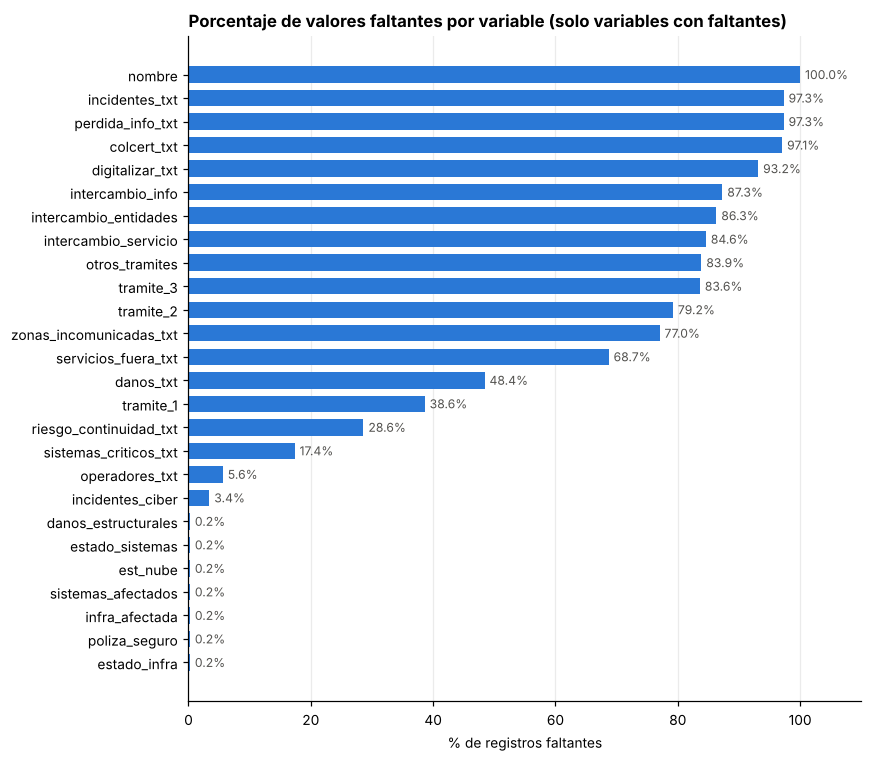

In [16]:
f = falt[falt.n_faltantes > 0].sort_values('%_faltantes')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(f.index, f['%_faltantes'], color=AZUL, height=.7)
for y, v in enumerate(f['%_faltantes']):
    ax.text(v + .8, y, f'{v:.1f}%', va='center', fontsize=8, color=GRIS)
ax.set_xlabel('% de registros faltantes'); ax.set_xlim(0, 110)
ax.set_title('Porcentaje de valores faltantes por variable (solo variables con faltantes)', loc='left')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [17]:
# ¿Los faltantes de texto libre son "estructurales"? (solo se responden si la pregunta filtro es afirmativa)
pares = [('riesgo_continuidad','riesgo_continuidad_txt'), ('zonas_incomunicadas','zonas_incomunicadas_txt'),
         ('danos_estructurales','danos_txt'), ('perdida_info','perdida_info_txt'), ('requiere_colcert','colcert_txt'),
         ('digitalizar','digitalizar_txt'), ('intercambio_afectado','intercambio_entidades')]
display(pd.DataFrame([{'pregunta_filtro': a, 'texto': b,
    '% texto lleno si filtro = Sí': round(df.loc[df[a].astype(str).str.startswith('Sí'), b].notna().mean()*100, 1),
    '% texto lleno si filtro ≠ Sí': round(df.loc[~df[a].astype(str).str.startswith('Sí'), b].notna().mean()*100, 1)} for a,b in pares]))

,pregunta_filtro,texto,% texto lleno si filtro = Sí,% texto lleno si filtro ≠ Sí
0,riesgo_continuidad,riesgo_continuidad_txt,98.3,34.3
1,zonas_incomunicadas,zonas_incomunicadas_txt,98.9,0.0
2,danos_estructurales,danos_txt,98.6,0.0
3,perdida_info,perdida_info_txt,100.0,0.0
4,requiere_colcert,colcert_txt,75.0,0.0
5,digitalizar,digitalizar_txt,93.3,0.0
6,intercambio_afectado,intercambio_entidades,80.0,10.3


**Variables más afectadas e impacto**

* Los faltantes se concentran en las **preguntas abiertas condicionales** (*"En caso afirmativo…"*): `perdida_info_txt`, `incidentes_txt`, `colcert_txt` y
  `digitalizar_txt` superan el 90 %; los trámites 2 y 3, los campos de intercambio y `zonas_incomunicadas_txt` están entre 77 % y 87 %. Son **faltantes estructurales**
  (MNAR por diseño del formulario): no se diligencian porque la pregunta filtro fue "No". No deben imputarse; para modelar se reemplazan por una
  indicadora (`tiene_texto = 0/1`) o se descartan.
* `nombre` está 100 % vacía y se elimina.
* Las variables **cerradas** prácticamente no tienen nulos (máximo 1 registro), y la **variable objetivo no tiene faltantes**, así que no se pierden observaciones para
  entrenar.
* El impacto real en las etapas siguientes viene de los **faltantes encubiertos** ("No se ha podido determinar"), que en algunas preguntas superan el 50 %. Si se
  trataran como nulos, la mitad de la base quedaría incompleta; por eso se mantienen como categoría explícita y se evalúa su relación con la variable objetivo.
* La información de texto libre (trámites prioritarios, servicios caídos) podría aprovecharse con técnicas de NLP en una fase posterior, pero no en el modelo base.

## 5. Análisis Univariado de Variables Cualitativas

In [18]:
def tabla_frec(s, orden=None):
    vc = s.value_counts(dropna=False)
    if orden is not None:
        vc = vc.reindex([o for o in orden if o in vc.index] + [i for i in vc.index if i not in orden])
    t = pd.DataFrame({'Frecuencia absoluta': vc, 'Frecuencia relativa (%)': (vc / vc.sum() * 100).round(1)})
    t['F. relativa acumulada (%)'] = t['Frecuencia relativa (%)'].cumsum().round(1)
    t.loc['Total'] = [vc.sum(), 100.0, np.nan]
    return t

def barras(s, titulo, orden=None, ax=None, color=AZUL):
    vc = s.value_counts()
    if orden is not None: vc = vc.reindex([o for o in orden if o in vc.index])
    vc = vc.iloc[::-1]
    ax = ax or plt.subplots(figsize=(7, .45*len(vc)+1))[1]
    ax.barh([str(i).rstrip('.') for i in vc.index], vc.values, color=color, height=.65)
    tot = s.notna().sum()
    for y, v in enumerate(vc.values):
        ax.text(v + tot*.005, y, f'{v} ({v/tot:.0%})', va='center', fontsize=8, color=GRIS)
    ax.set_xlim(0, vc.max()*1.2); ax.set_title(titulo, loc='left'); ax.grid(axis='y', visible=False)
    return ax

### 5.1 Tipo de entidad

,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
tipo_entidad,,,
Institución Educativa,259.0,63.3,63.3
Alcaldía,77.0,18.8,82.1
Hospital - ESE,28.0,6.8,88.9
Otro,26.0,6.4,95.3
Gobernación,9.0,2.2,97.5
Instituto descentralizado departamental,6.0,1.5,99.0
Instituto descentralizado municipal,4.0,1.0,100.0
Total,409.0,100.0,NaN


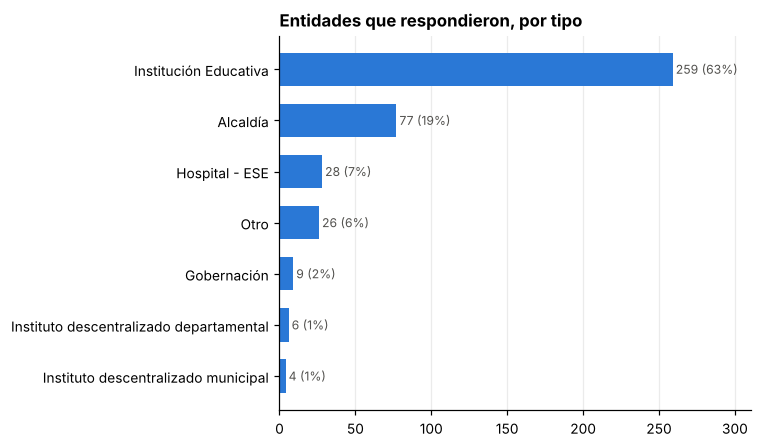

In [19]:
display(tabla_frec(df['tipo_entidad']))
barras(df['tipo_entidad'], 'Entidades que respondieron, por tipo'); plt.tight_layout(); plt.show()

Las **instituciones educativas** dominan la muestra (63 %), seguidas por las **alcaldías** (19 %). Hospitales, gobernaciones e institutos suman menos del 12 %.
La base, por tanto, describe sobre todo la situación de colegios; cualquier modelo tendrá muy pocos ejemplos de gobernaciones (9) e institutos (10), por lo que
conviene agruparlos (p. ej. *"Otras entidades territoriales"*) o incluir el tipo de entidad como variable de control.

### 5.2 Departamento

,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
departamento,,,
RISARALDA,170.0,41.6,41.6
VALLE DEL CAUCA,122.0,29.8,71.4
CALDAS,45.0,11.0,82.4
CHOCÓ,40.0,9.8,92.2
QUINDÍO,32.0,7.8,100.0
Total,409.0,100.0,NaN


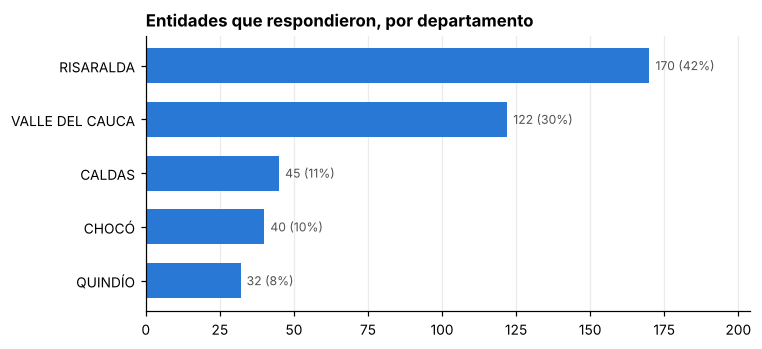

Municipios distintos: 108


,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
municipio,,,
BELÉN DE UMBRÍA,27.0,6.6,6.6
PUEBLO RICO,23.0,5.6,12.2
MARSELLA,15.0,3.7,15.9
QUINCHÍA,14.0,3.4,19.3
GUÁTICA,14.0,3.4,22.7
MANIZALES,12.0,2.9,25.6
LA CELIA,12.0,2.9,28.5
APÍA,12.0,2.9,31.4
SANTA ROSA DE CABAL,12.0,2.9,34.3


In [20]:
display(tabla_frec(df['departamento']))
barras(df['departamento'], 'Entidades que respondieron, por departamento'); plt.tight_layout(); plt.show()
print('Municipios distintos:', df['municipio'].nunique())
display(tabla_frec(df['municipio']).head(10))

**Risaralda (42 %) y Valle del Cauca (30 %)** concentran 7 de cada 10 respuestas; Caldas, Chocó y Quindío completan la base. Llama la atención que Chocó, departamento
del epicentro, tenga solo 40 respuestas (10 %): puede reflejar justamente su dificultad para responder (falta de conectividad), un **sesgo de respuesta** a tener en
cuenta. Hay 108 municipios, con Belén de Umbría y Pueblo Rico a la cabeza; por su alta cardinalidad, el municipio no se usará directamente como predictor.

### 5.3 Estado de la conectividad a Internet

,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
estado_conectividad,,,
Normal.,103.0,25.2,25.2
Degradada o inestable.,140.0,34.2,59.4
Disponible únicamente mediante mecanismos alternativos.,17.0,4.2,63.6
Sin conectividad.,149.0,36.4,100.0
Total,409.0,100.0,NaN


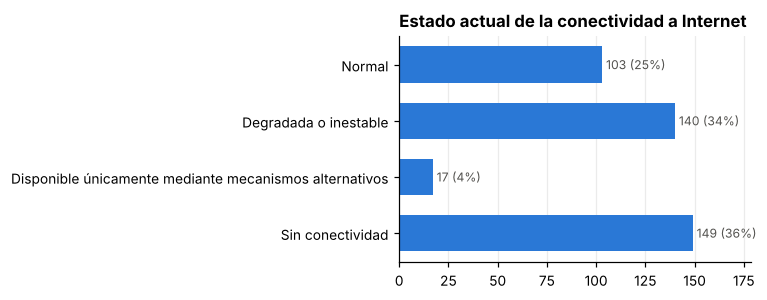

In [21]:
ORD_CONEC = ['Normal.', 'Degradada o inestable.', 'Disponible únicamente mediante mecanismos alternativos.', 'Sin conectividad.']
display(tabla_frec(df['estado_conectividad'], ORD_CONEC))
barras(df['estado_conectividad'], 'Estado actual de la conectividad a Internet', ORD_CONEC); plt.tight_layout(); plt.show()

Solo **1 de cada 4 entidades (25 %) tiene conectividad normal**. El 36 % está **sin conectividad** y el 34 % con conexión degradada o inestable. La conectividad
es el servicio más golpeado por el sismo y, como se verá, el candidato más fuerte para explicar el nivel de afectación.

### 5.4 Suministro de energía eléctrica y personal TIC

,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
energia_estable,,,
"Sí, normal.",310.0,75.8,75.8
"Sí, pero intermitente.",87.0,21.3,97.1
No.,12.0,2.9,100.0
Total,409.0,100.0,NaN


,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
personal_suficiente,,,
"Sí, cuenta con personal suficiente.",52.0,12.7,12.7
Cuenta parcialmente con personal.,67.0,16.4,29.1
No cuenta con personal técnico suficiente.,55.0,13.4,42.5
No cuenta actualmente con personal TIC.,203.0,49.6,92.1
No se ha podido determinar.,32.0,7.8,99.9
Total,409.0,100.0,NaN


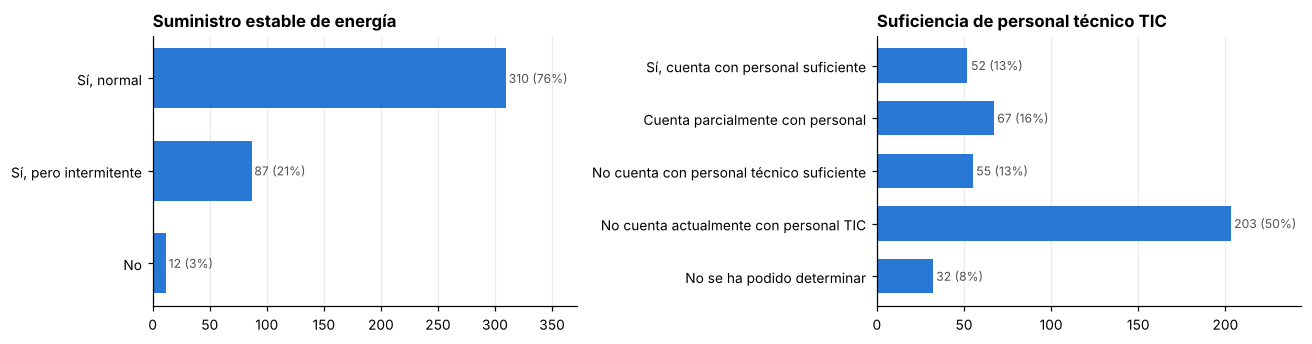

In [22]:
ORD_ENER = ['Sí, normal.', 'Sí, pero intermitente.', 'No.']
ORD_PERS = ['Sí, cuenta con personal suficiente.', 'Cuenta parcialmente con personal.', 'No cuenta con personal técnico suficiente.',
            'No cuenta actualmente con personal TIC.', 'No se ha podido determinar.']
display(tabla_frec(df['energia_estable'], ORD_ENER))
display(tabla_frec(df['personal_suficiente'], ORD_PERS))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
barras(df['energia_estable'], 'Suministro estable de energía', ORD_ENER, ax=axs[0])
barras(df['personal_suficiente'], 'Suficiencia de personal técnico TIC', ORD_PERS, ax=axs[1])
plt.tight_layout(); plt.show()

La **energía** se mantiene en la mayoría de entidades (76 % normal, 21 % intermitente, 3 % sin energía), así que no es el cuello de botella principal.
En cambio, la **capacidad humana** es muy limitada: el 50 % *no cuenta con personal TIC* y solo el 13 % tiene personal suficiente — lo que explica también la gran
cantidad de respuestas "No se ha podido determinar" en el resto del formulario.

### 5.5 Preguntas de selección múltiple: sistemas afectados y tipo de conexión

,Entidades que la marcan,% de entidades
sistemas_afectados,,
Otros.,265,64.8
Sistemas de información misionales.,67,16.4
Servicios de atención al ciudadano.,67,16.4
Servidores o centro de datos.,63,15.4
Sede electrónica o página web.,47,11.5
"Sistemas administrativos, financieros o de contratación.",38,9.3
Correo electrónico.,32,7.8
Servicios en la nube.,29,7.1
Bases de datos.,26,6.4


,Entidades que la marcan,% de entidades
tipo_conexion,,
Fibra óptica.,176,43.0
Radioenlace.,152,37.2
Satelital.,119,29.1
"Internet móvil 3G, 4G o 5G.",59,14.4
No sabe.,25,6.1
Otro.,14,3.4
Microondas.,5,1.2


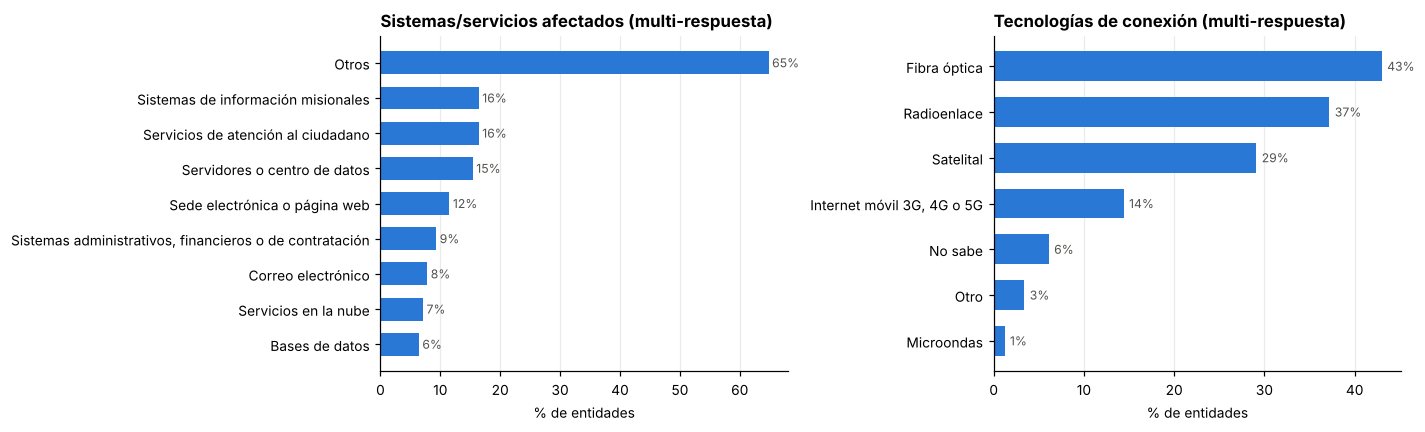

In [23]:
def multi(s):
    return s.fillna('').str.split(';').apply(lambda l: [x.strip() for x in l if x.strip()])

def tabla_multi(s):
    ex = multi(s).explode().dropna()
    vc = ex.value_counts()
    return pd.DataFrame({'Entidades que la marcan': vc, '% de entidades': (vc/len(s)*100).round(1)})

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, tit in [(axs[0], 'sistemas_afectados', 'Sistemas/servicios afectados (multi-respuesta)'),
                     (axs[1], 'tipo_conexion', 'Tecnologías de conexión (multi-respuesta)')]:
    t = tabla_multi(df[col]); display(t)
    t = t.iloc[::-1]
    ax.barh([i.rstrip('.') for i in t.index], t['% de entidades'], color=AZUL, height=.65)
    for y, v in enumerate(t['% de entidades']): ax.text(v+.6, y, f'{v:.0f}%', va='center', fontsize=8, color=GRIS)
    ax.set_xlabel('% de entidades'); ax.set_title(tit, loc='left'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

En las multi-respuesta los porcentajes no suman 100 %. En sistemas afectados domina la opción genérica **"Otros"** (65 %), lo que muestra que el formulario no recogía bien el
tipo de afectación de los colegios; entre las opciones específicas, los **sistemas misionales** y los **servicios de atención al ciudadano** (16 % cada uno) encabezan la lista. En conexión,
la **fibra óptica** y el **radioenlace** son las tecnologías más usadas, y un grupo relevante depende del **satélite**. De estas preguntas se derivarán variables
indicadoras (una por opción) y el número de opciones marcadas.

## 6. Análisis de la Variable Objetivo

,Definición en el formulario,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
nivel_afectacion_cat,,,,
Sin afectación TIC,la infraestructura y los servicios digitales operan normalmente.,47.0,11.5,11.5
Bajo,"afectaciones menores, sin impacto significativo en la continuidad.",56.0,13.7,25.2
Moderado,"afectaciones parciales con operación, aunque con limitaciones.",94.0,23.0,48.2
Alto,varios servicios o sistemas importantes presentan afectaciones que...,52.0,12.7,60.9
Crítico,imposibilidad de prestar servicios esenciales.,160.0,39.1,100.0
Total,,409.0,100.0,NaN


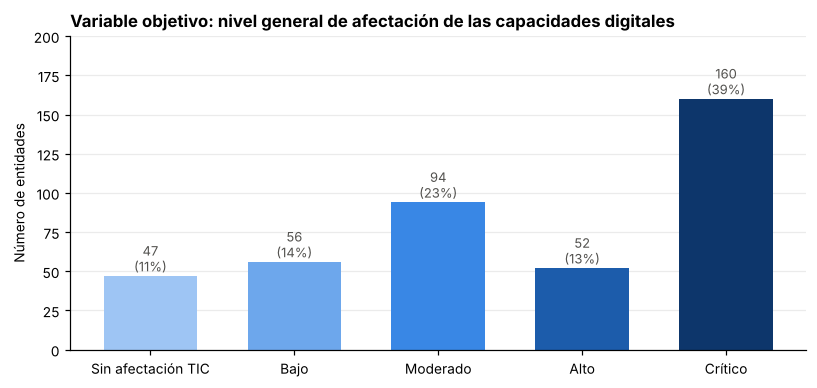

Mediana (código ordinal 0-4): 3.0 → Alto


In [24]:
ORD_OBJ = ['Sin afectación TIC', 'Bajo', 'Moderado', 'Alto', 'Crítico']
df['nivel_afectacion_cat'] = pd.Categorical(df['nivel_afectacion'].str.split(':').str[0].str.strip(), categories=ORD_OBJ, ordered=True)
df['nivel_afectacion_cod'] = df['nivel_afectacion_cat'].cat.codes   # 0 = Sin afectación ... 4 = Crítico
SEQ = ['#9ec5f4', '#6da7ec', '#3987e5', '#1c5cab', '#0d366b']   # rampa secuencial (claro = menor afectación)

t_obj = tabla_frec(df['nivel_afectacion_cat'].astype(str), ORD_OBJ)
t_obj.insert(0, 'Definición en el formulario', [df.loc[df.nivel_afectacion_cat==k, 'nivel_afectacion'].iloc[0].split(':',1)[1].strip() for k in ORD_OBJ] + [''])
display(t_obj)

vc = df['nivel_afectacion_cat'].value_counts().reindex(ORD_OBJ)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(ORD_OBJ, vc.values, color=SEQ, width=.65)
for x, v in enumerate(vc.values): ax.text(x, v+3, f'{v}\n({v/len(df):.0%})', ha='center', fontsize=8.5, color=GRIS)
ax.set_ylabel('Número de entidades'); ax.set_ylim(0, vc.max()*1.25); ax.grid(axis='x', visible=False)
ax.set_title('Variable objetivo: nivel general de afectación de las capacidades digitales', loc='left')
plt.tight_layout(); plt.show()
print('Mediana (código ordinal 0-4):', df['nivel_afectacion_cod'].median(), '→', ORD_OBJ[int(df['nivel_afectacion_cod'].median())])

| Atributo | Descripción |
|---|---|
| **Nombre** | `nivel_afectacion` (pregunta: *¿Cuál es el nivel general de afectación de las capacidades digitales como consecuencia del evento?*) |
| **Significado** | Autoevaluación de la entidad sobre qué tanto el sismo comprometió su capacidad de prestar servicios digitales |
| **Tipo** | Cualitativa **ordinal** de 5 niveles: Sin afectación TIC < Bajo < Moderado < Alto < Crítico |
| **Distribución** | Crítico 39 % · Moderado 23 % · Bajo 14 % · Alto 13 % · Sin afectación 11 %. Moda *Crítico* y mediana *Alto*: la distribución está cargada hacia los niveles graves |
| **Faltantes** | Ninguno |

**Justificación de la elección.** Es la variable que resume el estado de cada entidad y la que MinTIC necesita para **priorizar la respuesta**. Está
completa, tiene categorías bien definidas en el propio formulario y se puede explicar con el resto de las preguntas (conectividad, energía, estado de sistemas,
infraestructura, personal). Por ser categórica, el proyecto es de **clasificación**. Además, el formulario la define de forma cualitativa, por lo que un modelo
que la prediga a partir de indicadores objetivos sirve para **contrastar y estandarizar** la autoevaluación de las entidades.

## 7. Análisis Específico — 7.3 Clasificación
### 7.3.1 Número de clases, frecuencia relativa y desbalance

In [25]:
frec = df['nivel_afectacion_cat'].value_counts().reindex(ORD_OBJ)
print('Número de clases:', frec.size)
print('Frecuencia relativa:', (frec/frec.sum()*100).round(1).to_dict())
ratio = frec.max() / frec.min()
print(f'Razón de desbalance (clase mayor / clase menor): {frec.max()} / {frec.min()} = {ratio:.2f}')
p = frec/frec.sum(); H = -(p*np.log(p)).sum()/np.log(len(p))
print(f'Entropía normalizada (1 = perfectamente balanceado): {H:.3f}')
print(f'Exactitud de un clasificador ingenuo (predice siempre "Crítico"): {frec.max()/frec.sum():.1%}')

# Agrupación alternativa en 3 clases (útil si 5 clases resultan difíciles de separar con 409 registros)
MAP3 = {'Sin afectación TIC':'Baja o nula', 'Bajo':'Baja o nula', 'Moderado':'Moderada', 'Alto':'Alta o crítica', 'Crítico':'Alta o crítica'}
df['afectacion_3'] = pd.Categorical(df['nivel_afectacion_cat'].astype(str).map(MAP3), ['Baja o nula','Moderada','Alta o crítica'], ordered=True)
display(tabla_frec(df['afectacion_3'].astype(str), ['Baja o nula','Moderada','Alta o crítica']))

Número de clases: 5
Frecuencia relativa: {'Sin afectación TIC': 11.5, 'Bajo': 13.7, 'Moderado': 23.0, 'Alto': 12.7, 'Crítico': 39.1}
Razón de desbalance (clase mayor / clase menor): 160 / 47 = 3.40
Entropía normalizada (1 = perfectamente balanceado): 0.925
Exactitud de un clasificador ingenuo (predice siempre "Crítico"): 39.1%


,Frecuencia absoluta,Frecuencia relativa (%),F. relativa acumulada (%)
afectacion_3,,,
Baja o nula,103.0,25.2,25.2
Moderada,94.0,23.0,48.2
Alta o crítica,212.0,51.8,100.0
Total,409.0,100.0,NaN


Hay **5 clases** con un **desbalance moderado**: la clase *Crítico* (160) es 3,4 veces la clase menor (*Sin afectación*, 47). No es un desbalance extremo
(entropía normalizada ≈ 0,92), pero un modelo que siempre prediga *Crítico* acertaría el 39 % de las veces, así que la **exactitud no es una buena métrica**:
se usarán F1-macro y matriz de confusión, con validación estratificada y pesos por clase. Como alternativa, si el modelo de 5 clases no discrimina bien con
409 registros, se puede agrupar en 3 niveles (Baja o nula 25 %, Moderada 23 %, Alta o crítica 52 %).

### 7.3.2 Variables que podrían discriminar las clases

In [26]:
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2, p, dof, _ = chi2_contingency(t)
    n = t.values.sum(); r, k = t.shape
    phi2 = max(0, chi2/n - (k-1)*(r-1)/(n-1)); rc = r-(r-1)**2/(n-1); kc = k-(k-1)**2/(n-1)
    return np.sqrt(phi2 / max(1e-9, min(kc-1, rc-1))), p

# Variables derivadas
EST = [c for c in df.columns if c.startswith('est_')]
df['n_servicios_caidos'] = df[EST].isin(['Fuera de servicio.', 'Operativo con afectaciones.']).sum(axis=1)
for col, nuevo in [('sistemas_afectados','n_sistemas_afectados'), ('infra_afectada','n_infra_afectada'),
                   ('tipo_conexion','n_tipos_conexion'), ('energia_alternativa','n_energia_alt'), ('areas_apoyo','n_areas_apoyo')]:
    df[nuevo] = multi(df[col]).apply(len)

candidatas = ['departamento','tipo_entidad','riesgo_continuidad','estado_sistemas','energia_estable','estado_conectividad','zonas_incomunicadas',
              *EST,'sede_contingencia','estado_infra','danos_estructurales','poliza_seguro','perdida_info','backups','contingencia','control_cuentas',
              'proveedores_sla','requiere_colcert','personal_afectado','personal_suficiente','tramites_impedidos','digitalizar','intercambio_afectado']
assoc = pd.DataFrame([dict(zip(['variable','V_de_Cramer','p_valor'], [c, *cramers_v(df[c].fillna('NA'), df['nivel_afectacion_cat'])])) for c in candidatas])
assoc = assoc.sort_values('V_de_Cramer', ascending=False).reset_index(drop=True)
assoc['fuerza'] = pd.cut(assoc['V_de_Cramer'], [0, .1, .2, .3, 1], labels=['Despreciable','Débil','Moderada','Fuerte'])
assoc['p_valor'] = assoc['p_valor'].map(lambda v: f'{v:.1e}')
display(assoc)

,variable,V_de_Cramer,p_valor,fuerza
0,personal_afectado,0.582242,1.1e-56,Fuerte
1,est_sist_info,0.560816,4.1e-77,Fuerte
2,riesgo_continuidad,0.543944,2.6e-72,Fuerte
3,sede_contingencia,0.529054,1.7e-46,Fuerte
4,control_cuentas,0.512439,1.6e-43,Fuerte
5,zonas_incomunicadas,0.507654,1.1e-42,Fuerte
6,est_financiero,0.495529,2.2e-59,Fuerte
7,tramites_impedidos,0.483053,2.9e-56,Fuerte
8,est_web,0.478006,5.0e-55,Fuerte
9,perdida_info,0.477317,7.4e-55,Fuerte


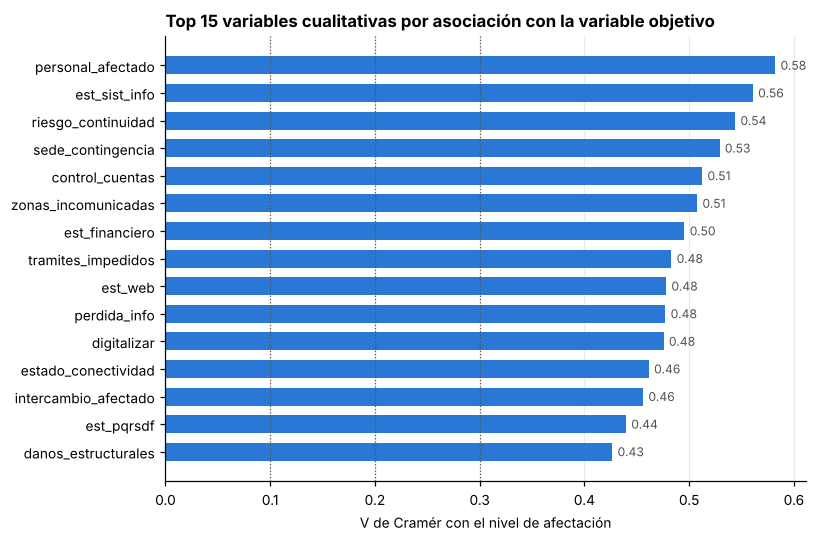

In [27]:
a = assoc.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(a['variable'], a['V_de_Cramer'], color=AZUL, height=.65)
for y, v in enumerate(a['V_de_Cramer']): ax.text(v+.005, y, f'{v:.2f}', va='center', fontsize=8, color=GRIS)
for x in (.1, .2, .3): ax.axvline(x, color=GRIS, lw=.8, ls=':')
ax.set_xlabel('V de Cramér con el nivel de afectación'); ax.grid(axis='y', visible=False)
ax.set_title('Top 15 variables cualitativas por asociación con la variable objetivo', loc='left')
plt.tight_layout(); plt.show()

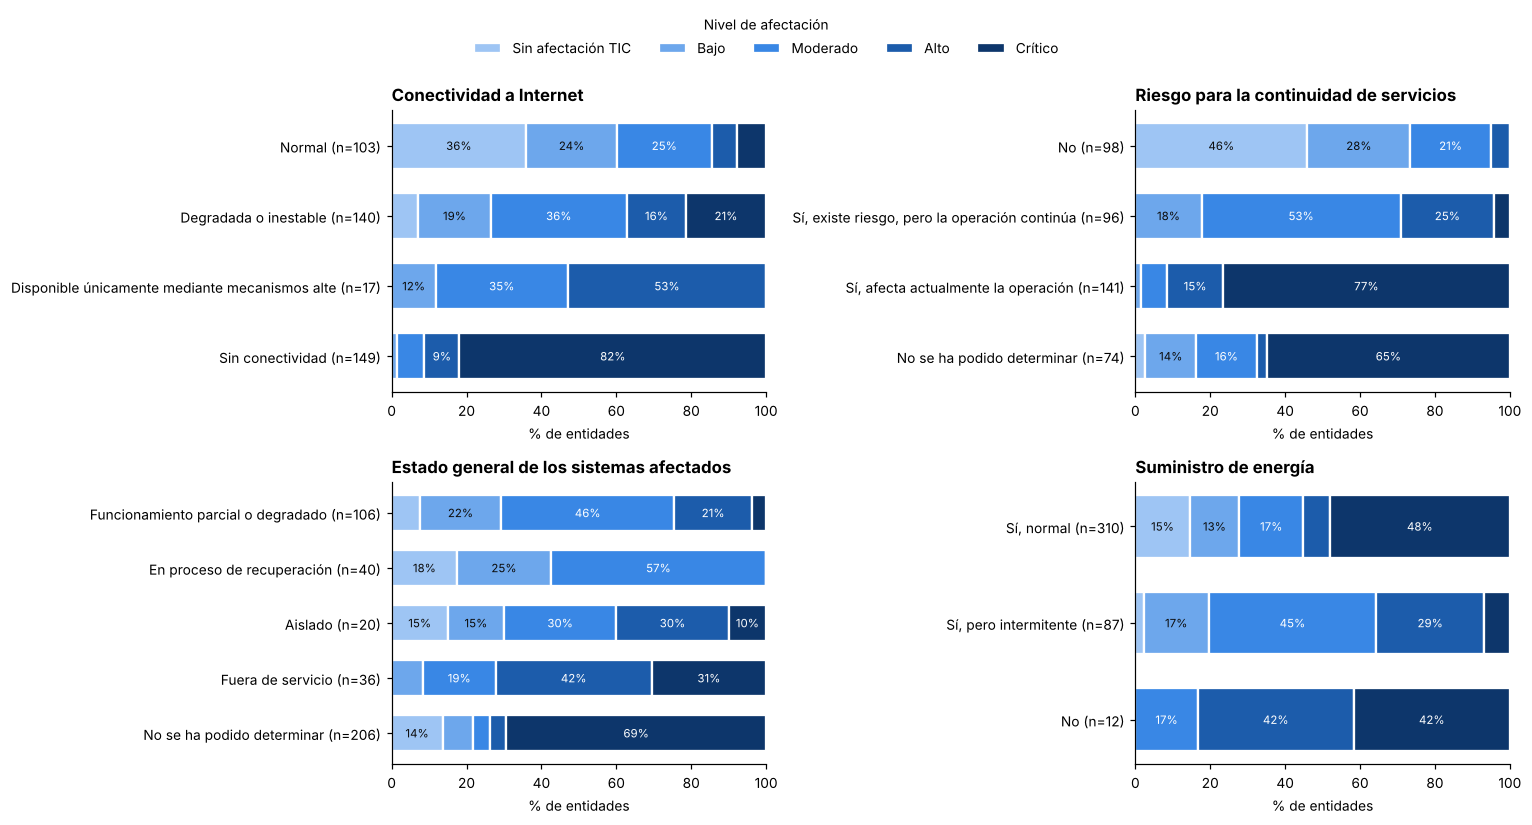

In [28]:
def apilado(col, orden, titulo, ax):
    t = pd.crosstab(df[col], df['nivel_afectacion_cat'], normalize='index').reindex([o for o in orden if o in df[col].unique()])*100
    n = df[col].value_counts().reindex(t.index)
    izq = np.zeros(len(t))
    etiquetas = [f"{str(i).rstrip('.')[:46]} (n={n[i]})" for i in t.index]
    for k, c in zip(ORD_OBJ, SEQ):
        ax.barh(etiquetas, t[k], left=izq, color=c, height=.65, label=k, edgecolor='white', linewidth=1.5)
        for y, (l, v) in enumerate(zip(izq, t[k])):
            if v >= 9: ax.text(l+v/2, y, f'{v:.0f}%', ha='center', va='center', fontsize=7.5, color='white' if k in ('Moderado','Alto','Crítico') else '#0b0b0b')
        izq += t[k].values
    ax.set_xlim(0, 100); ax.invert_yaxis(); ax.set_title(titulo, loc='left'); ax.grid(False); ax.set_xlabel('% de entidades')

fig, axs = plt.subplots(2, 2, figsize=(14, 7.5))
apilado('estado_conectividad', ORD_CONEC, 'Conectividad a Internet', axs[0,0])
apilado('riesgo_continuidad', ['No.','Sí, existe riesgo, pero la operación continúa.','Sí, afecta actualmente la operación.','No se ha podido determinar.'], 'Riesgo para la continuidad de servicios', axs[0,1])
apilado('estado_sistemas', ['Funcionamiento parcial o degradado.','En proceso de recuperación.','Aislado.','Fuera de servicio.','No se ha podido determinar.'], 'Estado general de los sistemas afectados', axs[1,0])
apilado('energia_estable', ORD_ENER, 'Suministro de energía', axs[1,1])
h, l = axs[0,0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=5, frameon=False, title='Nivel de afectación', bbox_to_anchor=(.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, .92)); plt.show()

nivel_afectacion_cat,Sin afectación TIC,Bajo,Moderado,Alto,Crítico
mediana por clase →,,,,,
n_servicios_caidos,0.000000,0.000000,2.000,2.000000,0.000000
n_sistemas_afectados,1.000000,1.000000,1.000,2.000000,1.000000
n_infra_afectada,1.000000,1.000000,2.000,2.000000,3.000000
n_tipos_conexion,1.000000,1.000000,1.000,1.000000,1.000000
n_energia_alt,1.000000,1.000000,1.000,1.000000,1.000000
n_areas_apoyo,1.000000,1.000000,2.000,2.000000,1.000000
duracion_min,14.333333,16.958333,20.575,20.408333,4.316667
dias_post_sismo,14.000000,14.000000,14.000,14.000000,15.000000


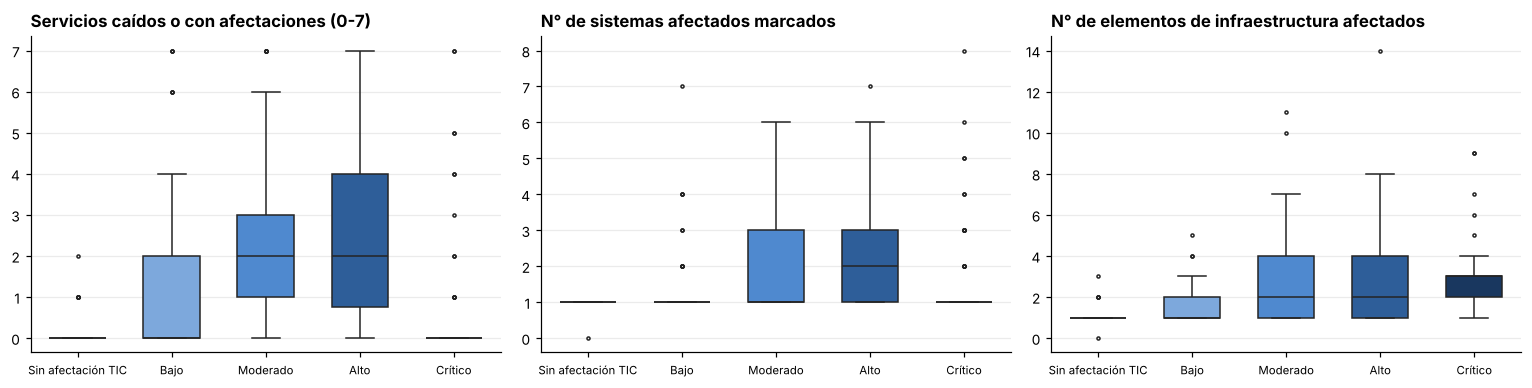

In [29]:
num = ['n_servicios_caidos','n_sistemas_afectados','n_infra_afectada','n_tipos_conexion','n_energia_alt','n_areas_apoyo','duracion_min','dias_post_sismo']
display(df.groupby('nivel_afectacion_cat', observed=True)[num].median().T.rename_axis('mediana por clase →'))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, c, tit in zip(axs, ['n_servicios_caidos','n_sistemas_afectados','n_infra_afectada'],
                      ['Servicios caídos o con afectaciones (0-7)','N° de sistemas afectados marcados','N° de elementos de infraestructura afectados']):
    sns.boxplot(data=df, x='nivel_afectacion_cat', y=c, order=ORD_OBJ, palette=SEQ, ax=ax, fliersize=2, width=.6)
    ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title(tit, loc='left'); ax.tick_params(axis='x', labelsize=7.5)
plt.tight_layout(); plt.show()

In [30]:
from scipy.stats import kruskal, spearmanr
res = []
for c in num:
    grupos = [g[c].dropna() for _, g in df.groupby('nivel_afectacion_cat', observed=True)]
    H, p = kruskal(*grupos); rho, _ = spearmanr(df[c], df['nivel_afectacion_cod'], nan_policy='omit')
    res.append({'variable': c, 'Kruskal-Wallis H': round(H, 1), 'p_valor': f'{p:.1e}', 'rho de Spearman': round(rho, 3)})
display(pd.DataFrame(res).sort_values('Kruskal-Wallis H', ascending=False))

,variable,Kruskal-Wallis H,p_valor,rho de Spearman
6,duracion_min,203.4,7.0e-43,-0.577
0,n_servicios_caidos,148.0,5.6e-31,-0.260
2,n_infra_afectada,101.8,4.0e-21,0.466
7,dias_post_sismo,71.0,1.4e-14,0.367
1,n_sistemas_afectados,66.4,1.3e-13,-0.001
5,n_areas_apoyo,39.3,6.1e-08,-0.135
4,n_energia_alt,28.4,1.0e-05,-0.191
3,n_tipos_conexion,7.1,1.3e-01,0.116


In [31]:
# Tabla cruzada por tipo de entidad (variable de control)
display((pd.crosstab(df['tipo_entidad'], df['nivel_afectacion_cat'], normalize='index')*100).round(1).assign(n=df['tipo_entidad'].value_counts()))

nivel_afectacion_cat,Sin afectación TIC,Bajo,Moderado,Alto,Crítico,n
tipo_entidad,,,,,,
Alcaldía,15.6,24.7,35.1,18.2,6.5,77
Gobernación,11.1,11.1,44.4,22.2,11.1,9
Hospital - ESE,14.3,32.1,42.9,10.7,0.0,28
Institución Educativa,6.6,8.1,15.4,12.0,57.9,259
Instituto descentralizado departamental,33.3,0.0,0.0,0.0,66.7,6
Instituto descentralizado municipal,50.0,25.0,25.0,0.0,0.0,4
Otro,34.6,19.2,38.5,7.7,0.0,26


### 7.3.3 Alerta: ¿cómo se generó la clase *Crítico*?

Entidades en Crítico: 160
  de Risaralda            : 145 (91%)
  instituciones educativas: 150 (94%)
  patrones distintos de respuestas cerradas: 61 ; el patrón más repetido aparece 65 veces


,mediana respuestas sin información,mediana minutos en el formulario
nivel_afectacion_cat,,
Sin afectación TIC,3.0,14.3
Bajo,3.5,17.0
Moderado,4.0,20.6
Alto,5.0,20.4
Crítico,19.0,4.3


nivel_afectacion_cat,Sin afectación TIC,Bajo,Moderado,Alto,Crítico
departamento,,,,,
CALDAS,33.0,24.0,24.0,11.0,7.0
CHOCÓ,2.0,28.0,45.0,20.0,5.0
QUINDÍO,12.0,22.0,47.0,19.0,0.0
RISARALDA,4.0,3.0,3.0,5.0,85.0
VALLE DEL CAUCA,17.0,18.0,37.0,20.0,8.0


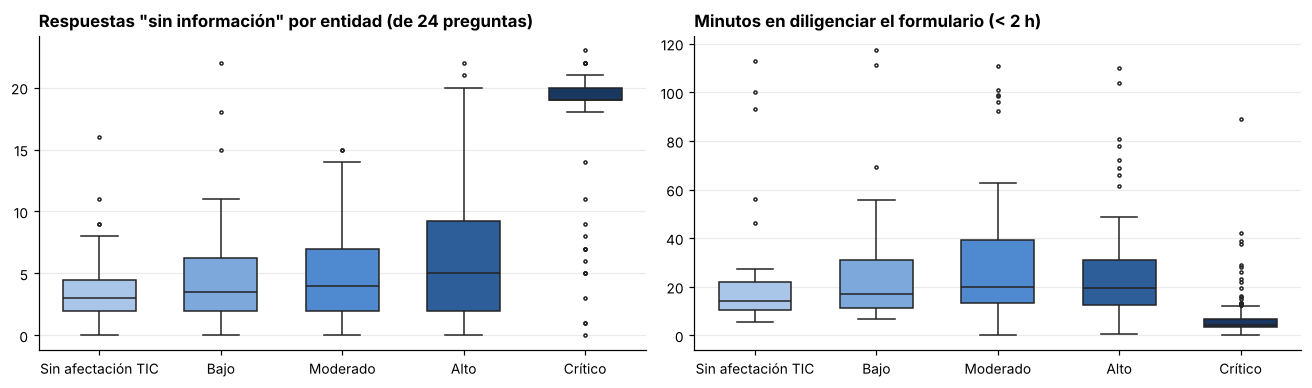

In [32]:
# Número de respuestas 'sin información' por entidad
cols_si = [c for c in cat_cols if df[c].isin(SIN_INFO).any()]
df['n_sin_info'] = df[cols_si].isin(SIN_INFO).sum(axis=1)
crit = df[df['nivel_afectacion_cat'] == 'Crítico']
print(f'Entidades en Crítico: {len(crit)}')
print(f'  de Risaralda            : {(crit.departamento=="RISARALDA").sum()} ({(crit.departamento=="RISARALDA").mean():.0%})')
print(f'  instituciones educativas: {(crit.tipo_entidad=="Institución Educativa").sum()} ({(crit.tipo_entidad=="Institución Educativa").mean():.0%})')
cerradas = [c for c in cat_cols if c not in ('departamento','tipo_entidad')]
patron = crit[cerradas].astype(str).agg('|'.join, axis=1)
print(f'  patrones distintos de respuestas cerradas: {patron.nunique()} ; el patrón más repetido aparece {patron.value_counts().iloc[0]} veces')
display(df.groupby('nivel_afectacion_cat', observed=True)[['n_sin_info','duracion_min']].median().round(1)
          .rename(columns={'n_sin_info':'mediana respuestas sin información','duracion_min':'mediana minutos en el formulario'}))
display((pd.crosstab(df['departamento'], df['nivel_afectacion_cat'], normalize='index')*100).round(0))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(data=df, x='nivel_afectacion_cat', y='n_sin_info', order=ORD_OBJ, palette=SEQ, ax=axs[0], fliersize=2, width=.6)
axs[0].set_title(f'Respuestas "sin información" por entidad (de {len(cols_si)} preguntas)', loc='left'); axs[0].set_xlabel(''); axs[0].set_ylabel('')
sns.boxplot(data=df[df.duracion_min<120], x='nivel_afectacion_cat', y='duracion_min', order=ORD_OBJ, palette=SEQ, ax=axs[1], fliersize=2, width=.6)
axs[1].set_title('Minutos en diligenciar el formulario (< 2 h)', loc='left'); axs[1].set_xlabel(''); axs[1].set_ylabel('')
plt.tight_layout(); plt.show()

La clase *Crítico* **no se distribuye como las demás**: 145 de sus 160 registros son de Risaralda (allí el 85 % de las entidades se declara *Crítico*), casi
todos son instituciones educativas, se diligenciaron en una mediana de ~4 minutos (frente a 14–21 en las otras clases), con una mediana de 19 respuestas
"sin información", y **65 registros comparten exactamente las mismas respuestas cerradas**. Todo indica un **diligenciamiento masivo** (por ejemplo, una secretaría
de educación reportando por sus sedes) más que 160 diagnósticos independientes.

**Implicaciones para la modelación:**
* Un modelo entrenado sin cuidado aprendería la regla *"colegio de Risaralda que no sabe responder → Crítico"*, con métricas altas pero poco útiles. Variables como
  `duracion_min`, `dias_post_sismo` o `n_sin_info` reflejan **cómo se llenó el formulario**, no el estado de la entidad, y se excluyen como predictores.
* Antes de entrenar se debe validar con MinTIC si estos registros son reales; como mínimo, se evaluará el modelo **con y sin** los registros repetidos y con
  validación agrupada por departamento o municipio.

**Hallazgos preliminares para discriminar las clases**

* Todas las variables operativas tienen asociación significativa con el nivel de afectación (p < 0,001). Las más fuertes (V de Cramér > 0,5) son la
  **afectación del personal TIC**, el **estado de los sistemas de información institucionales**, el **riesgo para la continuidad de servicios**, la necesidad de
  **sede electrónica de contingencia**, el **control de cuentas** y las **zonas incomunicadas**. El estado de la **conectividad** (V = 0,46) muestra un gradiente
  claro con los niveles de afectación.
* Parte de esa asociación está inflada por el bloque de registros de Risaralda descrito arriba (sus respuestas "No se ha podido determinar" coinciden con
  *Crítico*); el ranking de variables debe recalcularse sin ese bloque.
* Entre los **conteos derivados**, el número de elementos de infraestructura afectados crece con la gravedad (ρ = 0,47); el número de servicios caídos separa
  sobre todo *Moderado* y *Alto* del resto.
* **Departamento** (V = 0,41) y **tipo de entidad** (V = 0,27) funcionan como variables de control: en las alcaldías, hospitales y otras entidades predominan
  los niveles Moderado y Bajo, mientras que en los colegios predomina Crítico.
* El correo institucional casi siempre funciona (V = 0,12) y la necesidad de ColCERT apenas se relaciona con la afectación; aportan poco.

### 7.4 Pobreza del territorio y foco en el Chocó (cruce con el DANE)

**Pregunta de esta sección:** ¿las entidades ubicadas en municipios más pobres quedaron más afectadas por el terremoto, o con menos capacidad para
recuperarse? El Chocó es el caso central: es el departamento del epicentro y el más pobre de los cinco de la encuesta.

**Fuente complementaria:** Medida de Pobreza Multidimensional Municipal de fuente censal 2018, DANE
([página](https://www.dane.gov.co/index.php/estadisticas-por-tema/pobreza-y-condiciones-de-vida/pobreza-y-desigualdad/medida-de-pobreza-multidimensional-de-fuente-censal),
[anexo .xlsx](https://www.dane.gov.co/files/investigaciones/condiciones_vida/pobreza/2018/informacion-censal/anexo-censal-pobreza-municipal-2018.xlsx)).
Da el **IPM** (% de personas en pobreza multidimensional) de cada municipio, total, en cabeceras y en zona rural.

**Alcance y límites:**
* El IPM es del **municipio** y de **2018**: se interpreta como pobreza estructural del territorio, no como la situación actual de cada entidad.
* La encuesta es una sola foto posterior al sismo y no hay cifras de pobreza de 2026 todavía, así que esta sección **no mide si el terremoto aumentó la
  pobreza**. Mide si la pobreza previa del territorio se relaciona con la afectación y con la fragilidad digital de sus entidades.

In [33]:
ARCHIVO_IPM = ruta('anexo-censal-pobreza-municipal-2018.xlsx')
if not os.path.exists(ARCHIVO_IPM):
    try:
        from google.colab import files   # en Colab: subir el anexo del DANE
        files.upload()
    except ImportError:
        pass
import unicodedata, re
def normalizar(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
    s = re.sub(r'[^A-Z ]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

ipm = pd.read_excel(ARCHIVO_IPM, sheet_name='4_IPM Mpio dominios', dtype={'ID': str})
ipm.columns = ['cod_mpio', 'municipio_dane', 'ipm', 'ipm_cabecera', 'ipm_rural']
ipm['cod_dpto'] = ipm['cod_mpio'].str[:2]
ipm['clave'] = ipm['municipio_dane'].map(normalizar)
print('Municipios en el anexo del DANE:', len(ipm))

COD_DPTO = {'CALDAS': '17', 'CHOCÓ': '27', 'QUINDÍO': '63', 'RISARALDA': '66', 'VALLE DEL CAUCA': '76'}
df['cod_dpto'] = df['departamento'].map(COD_DPTO)
df['clave'] = df['municipio'].map(normalizar).replace({'SANTIAGO DE CALI': 'CALI'})   # el DANE lo nombra 'CALI'
df = df.drop(columns=[c for c in ['cod_mpio','ipm','ipm_cabecera','ipm_rural'] if c in df]) \
       .merge(ipm[['cod_dpto','clave','cod_mpio','ipm','ipm_cabecera','ipm_rural']], on=['cod_dpto','clave'], how='left')

mun = df[['departamento','municipio','ipm']].drop_duplicates()
print(f"Municipios de la encuesta emparejados: {mun.ipm.notna().sum()} de {len(mun)}")
print(f"Entidades con IPM: {df.ipm.notna().sum()} de {len(df)}")
print('Sin IPM:', df.loc[df.ipm.isna(), 'municipio'].unique().tolist(), '→ municipio creado en 2022, no existía en el Censo 2018')

Municipios en el anexo del DANE: 1122
Municipios de la encuesta emparejados: 107 de 108
Entidades con IPM: 408 de 409
Sin IPM: ['NUEVO BELÉN DE BAJIRÁ'] → municipio creado en 2022, no existía en el Censo 2018


,entidades,municipios,ipm_mediana,ipm_min,ipm_max
departamento,,,,,
QUINDÍO,32,12,19.9,14.4,33.1
VALLE DEL CAUCA,122,37,25.0,11.5,37.2
CALDAS,45,17,29.3,13.9,41.4
RISARALDA,170,14,35.6,13.7,70.5
CHOCÓ,40,28,63.4,44.4,90.6


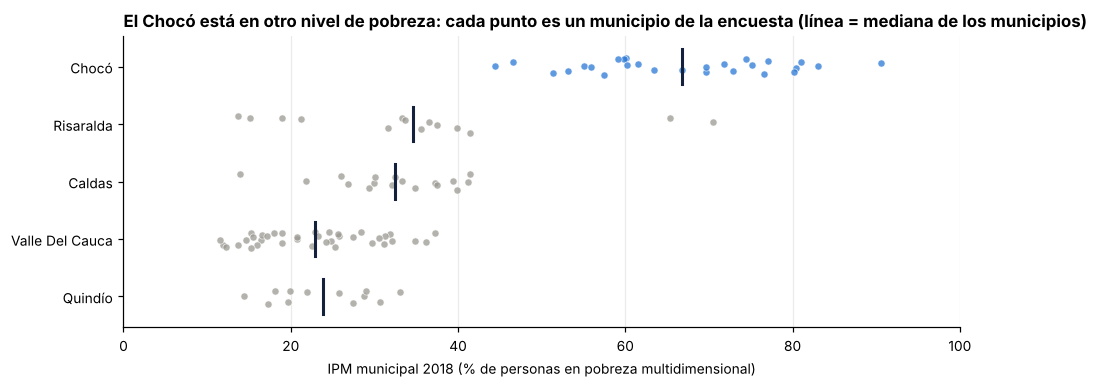

In [34]:
ORD_DPTO = df.groupby('departamento')['ipm'].median().sort_values().index.tolist()
t = df.groupby('departamento').agg(entidades=('id','size'), municipios=('municipio','nunique'),
                                   ipm_mediana=('ipm','median'), ipm_min=('ipm','min'), ipm_max=('ipm','max')).reindex(ORD_DPTO)
display(t.round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
pos = {d: i for i, d in enumerate(ORD_DPTO)}
rng = np.random.default_rng(1)
m_ = df[['departamento','municipio','ipm']].drop_duplicates().dropna()
for d, g in m_.groupby('departamento'):
    ax.scatter(g['ipm'], pos[d] + rng.uniform(-.15, .15, len(g)), s=22, alpha=.75,
               color=AZUL if d == 'CHOCÓ' else '#9a9890', edgecolor='white', linewidth=.5)
    ax.plot([g['ipm'].median()]*2, [pos[d]-.3, pos[d]+.3], color='#14213D', lw=2)
ax.set_yticks(range(len(ORD_DPTO))); ax.set_yticklabels([d.title() for d in ORD_DPTO])
ax.set_xlabel('IPM municipal 2018 (% de personas en pobreza multidimensional)'); ax.set_xlim(0, 100)
ax.set_title('El Chocó está en otro nivel de pobreza: cada punto es un municipio de la encuesta (línea = mediana de los municipios)', loc='left')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

Las entidades del **Chocó** están en municipios con un IPM mediano de **63 %**, entre 44 % y 91 % (Alto Baudó). Los municipios de los otros
cuatro departamentos están casi todos por debajo de 40 %. Ningún municipio del Chocó en la encuesta tiene un IPM tan bajo como el más pobre de Quindío o Valle.
Es decir, el departamento no es solo más pobre en promedio: **toda su distribución está desplazada**.

In [35]:
d = df.dropna(subset=['ipm']).copy()
filas = []
for nombre, s in [('Todas las entidades', d), ('Sin Risaralda', d[d.departamento != 'RISARALDA']),
                  ('Solo alcaldías', d[d.tipo_entidad == 'Alcaldía']), ('Solo instituciones educativas', d[d.tipo_entidad == 'Institución Educativa'])]:
    rho, p = spearmanr(s['ipm'], s['nivel_afectacion_cod'])
    H, pk = kruskal(*[g['ipm'] for _, g in s.groupby('nivel_afectacion_cat', observed=True)])
    med = s.groupby('nivel_afectacion_cat', observed=True)['ipm'].median().reindex(ORD_OBJ)
    filas.append({'grupo': nombre, 'n': len(s), 'rho de Spearman': round(rho, 2), 'p (Spearman)': f'{p:.3f}', 'p (Kruskal-Wallis)': f'{pk:.3f}',
                  **{f'IPM mediano · {k}': round(v, 1) for k, v in med.items()}})
display(pd.DataFrame(filas).set_index('grupo'))

,n,rho de Spearman,p (Spearman),p (Kruskal-Wallis),IPM mediano · Sin afectación TIC,IPM mediano · Bajo,IPM mediano · Moderado,IPM mediano · Alto,IPM mediano · Crítico
grupo,,,,,,,,,
Todas las entidades,408,0.35,0.000,0.000,25.8,30.1,28.6,29.9,35.9
Sin Risaralda,238,0.15,0.022,0.073,20.8,29.1,28.8,26.8,25.7
Solo alcaldías,77,0.08,0.512,0.240,32.7,41.4,35.6,45.7,29.7
Solo instituciones educativas,259,0.52,0.000,0.000,20.7,22.0,29.3,29.7,36.5


**¿Más pobreza, más afectación?** Con toda la base la respuesta parece ser sí (ρ ≈ 0,35, p < 0,001), pero esa relación **depende del bloque de Risaralda**
(sección 7.3.3): sus colegios en *Crítico* están en municipios de pobreza media-alta. Al quitar Risaralda la relación se vuelve débil (ρ ≈ 0,15) y, entre
alcaldías, desaparece. **La pobreza del municipio no explica por sí sola cuánta afectación declara una entidad.**

Cortes de los terciles de IPM: {'IPM bajo': {'min': 11.5, 'max': 26.0}, 'IPM medio': {'min': 26.8, 'max': 36.5}, 'IPM alto': {'min': 37.2, 'max': 90.6}}
% de entidades con cada condición, por tercil de IPM (sin Risaralda, n = 238 )


ipm_grupo,IPM bajo,IPM medio,IPM alto,rho con IPM,p
sin_energia_estable,27.0,28.0,58.0,0.25,0.000
sin_fibra_optica,35.0,34.0,58.0,0.13,0.052
depende_satelite,13.0,18.0,53.0,0.32,0.000
sin_poliza,39.0,32.0,49.0,0.08,0.248
sin_contingencia,40.0,47.0,51.0,0.10,0.133
personal_insuficiente,48.0,50.0,47.0,0.04,0.581


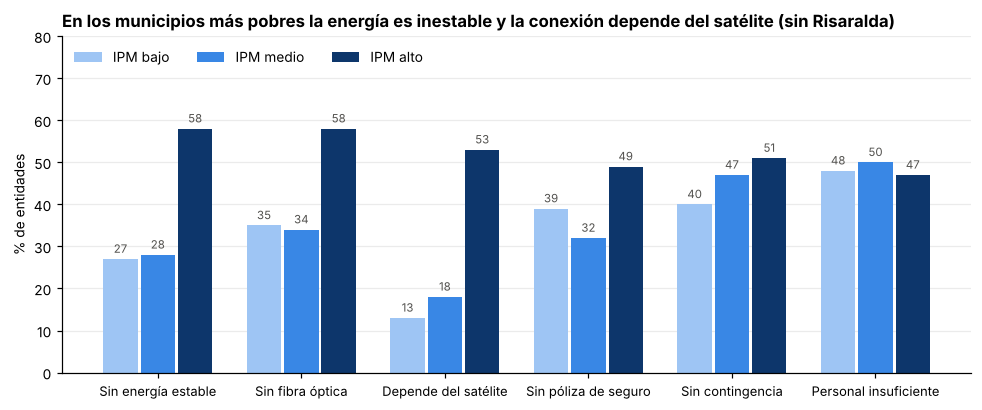

In [36]:
# Indicadores de fragilidad digital, definidos a partir de la encuesta (1 = condición desfavorable)
d['sin_energia_estable'] = (d['energia_estable'] != 'Sí, normal.').astype(int)
d['sin_fibra_optica']    = (~d['tipo_conexion'].str.contains('Fibra', na=False)).astype(int)
d['depende_satelite']    = d['tipo_conexion'].str.contains('Satelital', na=False).astype(int)
d['sin_poliza']          = (d['poliza_seguro'] == 'No.').astype(int)
d['sin_contingencia']    = (d['contingencia'] == 'No existen.').astype(int)
d['personal_insuficiente'] = d['personal_suficiente'].isin(['No cuenta actualmente con personal TIC.', 'No cuenta con personal técnico suficiente.']).astype(int)
FRAG = ['sin_energia_estable','sin_fibra_optica','depende_satelite','sin_poliza','sin_contingencia','personal_insuficiente']

d['ipm_grupo'] = pd.qcut(d['ipm'], 3, labels=['IPM bajo', 'IPM medio', 'IPM alto'])
print('Cortes de los terciles de IPM:', d.groupby('ipm_grupo', observed=True)['ipm'].agg(['min','max']).round(1).to_dict('index'))
sr = d[d.departamento != 'RISARALDA']
tab = (sr.groupby('ipm_grupo', observed=True)[FRAG].mean()*100).round(0).T
tab['rho con IPM'] = [round(spearmanr(sr['ipm'], sr[c])[0], 2) for c in FRAG]
tab['p'] = [f"{spearmanr(sr['ipm'], sr[c])[1]:.3f}" for c in FRAG]
print('% de entidades con cada condición, por tercil de IPM (sin Risaralda, n =', len(sr), ')')
display(tab)

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(FRAG)); w = .26
for i, (g, c) in enumerate(zip(['IPM bajo','IPM medio','IPM alto'], ['#9ec5f4', '#3987e5', '#0d366b'])):
    v = tab[g].values; ax.bar(x + (i-1)*w, v, w*.92, color=c, label=g)
    for xi, vi in zip(x + (i-1)*w, v): ax.text(xi, vi + 1.5, f'{vi:.0f}', ha='center', fontsize=7.5, color=GRIS)
ETQ = {'sin_energia_estable':'Sin energía estable','sin_fibra_optica':'Sin fibra óptica','depende_satelite':'Depende del satélite','sin_poliza':'Sin póliza de seguro','sin_contingencia':'Sin contingencia','personal_insuficiente':'Personal insuficiente'}
ax.set_xticks(x); ax.set_xticklabels([ETQ[f] for f in FRAG], fontsize=8.5)
ax.set_ylabel('% de entidades'); ax.set_ylim(0, 80); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncol=3, loc='upper left')
ax.set_title('En los municipios más pobres la energía es inestable y la conexión depende del satélite (sin Risaralda)', loc='left')
plt.tight_layout(); plt.show()

**Donde sí pesa la pobreza es en la fragilidad de la infraestructura.** Sin el bloque de Risaralda, en los municipios del tercil de IPM más alto el
**58 %** de las entidades tiene energía inestable (frente a 27 % en el tercil bajo) y el **53 %** depende de internet satelital (frente a 13 %). Ambas relaciones
son significativas. En cambio, la falta de pólizas, de planes de contingencia o de personal TIC es común en todos los niveles de pobreza.

In [37]:
# Índice de vulnerabilidad digital (0 a 5): suma de condiciones desfavorables definidas de antemano
COMP = ['sin_energia_estable','sin_fibra_optica','sin_poliza','sin_contingencia','personal_insuficiente']
d['indice_vulnerabilidad'] = d[COMP].sum(axis=1)
sr = d[d.departamento != 'RISARALDA']
iv = d.groupby('departamento').agg(n=('id','size'), ipm_mediana=('ipm','median'), indice_medio=('indice_vulnerabilidad','mean')).sort_values('ipm_mediana')
display(iv.round(2))
rho, p = spearmanr(sr['ipm'], sr['indice_vulnerabilidad'])
print(f'Correlación IPM vs índice de vulnerabilidad (sin Risaralda): rho = {rho:.2f}, p = {p:.3f}')

,n,ipm_mediana,indice_medio
departamento,,,
QUINDÍO,32,19.90,0.97
VALLE DEL CAUCA,122,25.05,2.20
CALDAS,45,29.30,1.96
RISARALDA,170,35.60,1.81
CHOCÓ,39,63.40,2.67


Correlación IPM vs índice de vulnerabilidad (sin Risaralda): rho = 0.20, p = 0.002


In [38]:
# Chocó frente al resto, comparando solo alcaldías (Chocó: 29 de sus 40 respuestas son alcaldías)
from scipy.stats import fisher_exact
a = df[df.tipo_entidad == 'Alcaldía'].copy()
a['grupo'] = np.where(a.departamento == 'CHOCÓ', 'Chocó', 'Otros 4 departamentos')
ind = {
 'Energía intermitente o sin energía': a.energia_estable != 'Sí, normal.',
 'Depende de internet satelital': a.tipo_conexion.str.contains('Satelital', na=False),
 'Tiene fibra óptica': a.tipo_conexion.str.contains('Fibra', na=False),
 'Conectividad no normal': a.estado_conectividad != 'Normal.',
 'Infraestructura con póliza de seguro': a.poliza_seguro == 'Sí.',
 'No tiene mecanismos de contingencia': a.contingencia == 'No existen.',
 'Requiere apoyo de ColCERT': a.requiere_colcert == 'Sí.',
 'Se declara "Sin afectación TIC"': a.nivel_afectacion_cat == 'Sin afectación TIC',
 'Se declara Alto o Crítico': a.nivel_afectacion_cat.isin(['Alto', 'Crítico']),
}
filas = []
for k, cond in ind.items():
    t = pd.crosstab(a['grupo'], cond).reindex(columns=[False, True], fill_value=0)
    filas.append({'Indicador (alcaldías)': k,
                  'Chocó (%)': round(t.loc['Chocó', True] / t.loc['Chocó'].sum() * 100),
                  'Otros 4 deptos (%)': round(t.loc['Otros 4 departamentos', True] / t.loc['Otros 4 departamentos'].sum() * 100),
                  'p (Fisher)': f'{fisher_exact(t.values)[1]:.3f}'})
print(a['grupo'].value_counts().to_dict())
display(pd.DataFrame(filas).set_index('Indicador (alcaldías)'))

{'Otros 4 departamentos': 48, 'Chocó': 29}


,Chocó (%),Otros 4 deptos (%),p (Fisher)
Indicador (alcaldías),,,
Energía intermitente o sin energía,69,33,0.004
Depende de internet satelital,66,10,0.000
Tiene fibra óptica,45,85,0.000
Conectividad no normal,66,44,0.099
Infraestructura con póliza de seguro,10,35,0.017
No tiene mecanismos de contingencia,48,33,0.232
Requiere apoyo de ColCERT,17,2,0.026
"Se declara ""Sin afectación TIC""",3,23,0.025
Se declara Alto o Crítico,28,23,0.786


**Hallazgos de la sección 7.4**

* **Pobreza ≠ más afectación declarada.** La relación entre IPM y nivel de afectación se explica casi toda por el bloque de Risaralda; sin él es débil.
* **Pobreza = infraestructura más frágil.** En los municipios más pobres las entidades dependen más del satélite y tienen energía inestable; el índice de
  vulnerabilidad digital crece con el IPM.
* **Chocó, el caso extremo.** Sus alcaldías tienen el doble de energía inestable que las de los otros departamentos, seis veces más dependencia del satélite,
  menos pólizas y más necesidad de ColCERT; además, casi ninguna se declara "Sin afectación".
* **Lectura de política.** Si MinTIC prioriza solo por lo que cada entidad declara, el Chocó puede quedar relegado (declara Moderado, no Crítico), aunque es
  donde la infraestructura es más frágil y la recuperación más difícil. El IPM y el índice de vulnerabilidad aportan un criterio territorial que la
  autoevaluación no captura.
* **Pendiente:** cuando el DANE publique la pobreza de 2026 (previsiblemente en 2027) se podrá comparar antes y después del sismo; con los datos actuales esa
  pregunta no se puede responder.
* Advertencias: pocas observaciones (40 entidades del Chocó, 29 alcaldías), datos autorreportados e IPM de 2018.

## 8. Planteamiento del Problema de Analítica de Datos

> **¿Es posible clasificar el nivel de afectación de las capacidades digitales (Sin afectación, Bajo, Moderado, Alto o Crítico) de una entidad pública después del
> terremoto, a partir de su reporte sobre conectividad, energía, estado de sistemas e infraestructura TIC y capacidad de personal técnico, y de la pobreza
> multidimensional de su municipio, para que MinTIC priorice el apoyo hacia las entidades y territorios más vulnerables, como el Chocó?**

* **¿Qué se desea predecir?** El nivel de afectación digital de cada entidad (variable ordinal de 5 clases, o 3 clases agrupadas).
* **¿Para qué?** Para priorizar y focalizar la respuesta de MinTIC (conectividad de emergencia, energía de respaldo, apoyo técnico, sede electrónica de
  contingencia, ColCERT) y para contar con un criterio objetivo que complemente la autoevaluación de cada entidad.
* **¿Con qué información?** Con las respuestas cerradas de la encuesta de 409 entidades: estado de conectividad y energía, estado de 7 servicios digitales,
  infraestructura y daños físicos, respaldo y contingencia, personal TIC, tipo de entidad y departamento, más las variables derivadas de conteo; y el
  **IPM municipal del DANE** (Censo 2018) con el índice de vulnerabilidad digital construido en la sección 7.4.

**Pregunta complementaria (descriptiva):** ¿las entidades de los municipios más pobres, en particular las del Chocó, tienen una infraestructura digital más frágil
frente a desastres? La sección 7.4 muestra que sí, aunque no declaran más afectación. *Si el terremoto aumentó la pobreza no se puede responder aún: requiere cifras
de pobreza de 2026 que el DANE no ha publicado.*

## 9. Objetivo de Modelación

**Objetivo general.** Desarrollar un modelo de clasificación supervisada que prediga el nivel de afectación de las capacidades digitales de las entidades públicas
afectadas por el terremoto del 10 de agosto de 2026, en función de su estado de conectividad, energía, servicios digitales, infraestructura TIC, capacidad de
personal técnico y pobreza multidimensional del municipio, como insumo para priorizar la atención de MinTIC con un criterio territorial que incluya al Chocó.

**Objetivos específicos.**
1. Preparar la base para modelación: verificar con MinTIC el bloque de registros repetidos de Risaralda, depurar duplicados y variables sin información, tratar las respuestas *"No se ha podido determinar"* como categoría
   propia, codificar las variables ordinales y las multi-respuesta (indicadoras y conteos).
2. Identificar las variables que más discriminan los niveles de afectación mediante pruebas de asociación (V de Cramér, Kruskal-Wallis) e importancia de
   variables del modelo.
3. Entrenar y comparar al menos tres clasificadores (regresión logística multinomial u ordinal como línea base, árbol de decisión y Random Forest / Gradient
   Boosting), con validación cruzada estratificada y ponderación de clases.
4. Medir el aporte del IPM municipal y del índice de vulnerabilidad digital al modelo, y comparar el desempeño en el Chocó frente al resto de departamentos.
5. Evaluar los modelos con F1-macro, recall de la clase *Crítico* y matriz de confusión, y seleccionar el que mejor equilibre desempeño e interpretabilidad para
   la toma de decisiones.

**Propuesta de modelo.** Línea base: regresión logística multinomial (interpretable). Modelo principal: **Random Forest** con `class_weight='balanced'`, adecuado
para muchas variables categóricas, pocas observaciones y relaciones no lineales. Validación cruzada estratificada de 5 pliegues (y una prueba agrupada por departamento para medir generalización); métrica principal F1-macro. Se excluyen como
predictores los metadatos del formulario (duración, fecha, número de respuestas sin información).

In [39]:
# Exportar base con nombres cortos y variables derivadas (insumo para la siguiente fase)
excluir = ['correo','nombre','autoriza_datos','incidentes_ciber']
df.drop(columns=excluir + ['clave']).to_csv(PROC / 'base_lab1_preparada.csv', index=False, encoding='utf-8-sig')
d.drop(columns=excluir + ['clave']).to_csv(PROC / 'base_lab1_con_ipm.csv', index=False, encoding='utf-8-sig')
print('Exportados: diccionario_variables.csv, base_lab1_preparada.csv', df.drop(columns=excluir + ['clave']).shape,
      'y base_lab1_con_ipm.csv (con IPM e índice de vulnerabilidad)', d.drop(columns=excluir + ['clave']).shape)

Exportados: diccionario_variables.csv, base_lab1_preparada.csv (409, 74) y base_lab1_con_ipm.csv (con IPM e índice de vulnerabilidad) (408, 82)
